# ExplainPhish: PDF Phishing Detection
## Exploratory Data Analysis & Machine Learning Benchmark
**Role**: Senior Lead Data Scientist & Security Machine Learning Specialist  
**Dataset**: `PDF_Top10_features.csv` (19,296 instances, 10 extracted PDF structural & stream features, 1 target label)

---

### Objectives
1. **Load and clean** dataset (drop trailing delimiter export artifacts `Unnamed: 11..19`).
2. **Progressive Feature Selection**: 5-feature baseline subset vs. complete 10-feature pool.
3. **Data Quality & Missing Values Audit**: Audit structural stream properties and header integrity.
4. **Target Distribution & Feature Deep Dive**: Distributions, skewness, Mann-Whitney U tests, and cybersecurity threat context for all 10 features.
5. **Linearity vs. Non-Linearity**: Mutual Information vs. Pearson $r$, Binned Scatter Plots with linear vs. polynomial curve fits, and 2D decision boundary scatter plots.
6. **Preprocessing & Artifact Export**: Stratified 80/20 train/test split, log1p variance stabilization, and standardized CSV dataset exports.
7. **Model Comparison**: Benchmark Neural Network (MLP), Random Forest, Decision Tree, XGBoost, and LightGBM with ROC curves and confusion matrices.
8. **PCA Experiment**: Scree plot, cumulative variance curve, and model performance comparison with vs. without PCA.


## 1. Setup & Library Imports
We configure scientific Python libraries and visualization parameters.


In [1]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Environment configured successfully!")


Environment configured successfully!


## 2. Loading the Data
### 2.1 Data Overview & Cleaning
We load `PDF_Top10_features.csv`, prune unnamed delimiter artifacts, and inspect column schemas.


In [2]:
possible_paths = [
    Path("data/pdf/PDF_Top10_features.csv"),
    Path("../data/pdf/PDF_Top10_features.csv"),
    Path("trainingModel/data/pdf/PDF_Top10_features.csv"),
    Path(r"d:/codingProject/ExplainPhish/trainingModel/data/pdf/PDF_Top10_features.csv")
]

data_path = next((p for p in possible_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Could not find PDF_Top10_features.csv")

print(f"Loading data from: {data_path.resolve()}")
raw_df = pd.read_csv(data_path)

# Drop trailing unnamed artifact columns
clean_cols = [c for c in raw_df.columns if not c.lower().startswith("unnamed")]
df = raw_df[clean_cols].copy()

if "file_name" not in df.columns:
    df.insert(0, "file_name", [f"sample_{i+1:05d}.pdf" for i in range(len(df))])

print(f"Cleaned dataset shape: {df.shape[0]:,} rows | {df.shape[1]} columns")
df.head(5)


Loading data from: D:\codingProject\ExplainPhish\trainingModel\data\pdf\PDF_Top10_features.csv
Cleaned dataset shape: 19,296 rows | 12 columns


,file_name,text_length,total_filters,title_chars,file_size,object_count,stream_count,endstream_count,metadata_size,valid_pdf_header,entropy_of_streams,label
0,sample_00001.pdf,8018,8,8,20362,120,18,9,254,1,6.0102,0
1,sample_00002.pdf,11568,7,35,28848,36,16,8,242,1,6.2401,0
2,sample_00003.pdf,1377,2,12,76563,21,4,2,138,1,5.8304,0
3,sample_00004.pdf,30607,11,8,67982,46,26,13,278,1,6.3170,0
4,sample_00005.pdf,9944,5,62,14469,25,12,6,399,1,6.3008,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19296 entries, 0 to 19295
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   file_name           19296 non-null  str    
 1   text_length         19296 non-null  int64  
 2   total_filters       19296 non-null  int64  
 3   title_chars         19296 non-null  int64  
 4   file_size           19296 non-null  int64  
 5   object_count        19296 non-null  int64  
 6   stream_count        19296 non-null  int64  
 7   endstream_count     19296 non-null  int64  
 8   metadata_size       19296 non-null  int64  
 9   valid_pdf_header    19296 non-null  int64  
 10  entropy_of_streams  19296 non-null  float64
 11  label               19296 non-null  int64  
dtypes: float64(1), int64(10), str(1)
memory usage: 1.8 MB


### 2.2 Selecting Features

> **Data Science Principle:**  
> It is often difficult to perform data analysis and preprocessing on all features simultaneously from the beginning. Instead, an established best practice is to **start with a small, high-signal subset of features** to establish a baseline, and then **iteratively add features one by one**.

Here, we define:
- Target column: `label` (0 = Benign, 1 = Malicious / Phishing).
- Identifier column: `file_name`.
- Full feature pool (10 features).
- Initial Core Baseline Subset (5 features):
  1. `stream_count` (Binary stream volume)
  2. `object_count` (PDF structural complexity)
  3. `entropy_of_streams` (Payload encryption / compression)
  4. `total_filters` (Obfuscation evasion filter chains)
  5. `file_size` (Payload byte scale)


In [4]:
target_col = 'label'
id_col = 'file_name'

all_features = [col for col in df.columns if col not in [target_col, id_col]]

use_features = [
    "stream_count",
    "object_count",
    "entropy_of_streams",
    "total_filters",
    "file_size"
]

print(f"Total features available : {len(all_features)}")
print(f"Initial selected features: {len(use_features)} -> {use_features}")
df[[id_col] + use_features + [target_col]].head(5)


Total features available : 10
Initial selected features: 5 -> ['stream_count', 'object_count', 'entropy_of_streams', 'total_filters', 'file_size']


,file_name,stream_count,object_count,entropy_of_streams,total_filters,file_size,label
0,sample_00001.pdf,18,120,6.0102,8,20362,0
1,sample_00002.pdf,16,36,6.2401,7,28848,0
2,sample_00003.pdf,4,21,5.8304,2,76563,0
3,sample_00004.pdf,26,46,6.3170,11,67982,0
4,sample_00005.pdf,12,25,6.3008,5,14469,0


## 3. Visualizing and Understanding the Data
We audit missing values, class balance, and parametric vs. non-parametric feature characteristics.


### 3.1 Checking Missing Values
We verify data completeness after pruning export artifacts.


In [5]:
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    'Feature': df.columns,
    'Missing Count': missing_counts.values,
    'Missing (%)': missing_percent.values
}).sort_values(by='Missing Count', ascending=False)

print("Missing values audit (Clean Data):")
print(missing_df.to_string(index=False))

# Check structural zeros
zero_summary = pd.DataFrame({
    'Feature': all_features,
    'Zero Count': (df[all_features] == 0).sum().values,
    'Zero (%)': ((df[all_features] == 0).sum() / len(df) * 100).round(2).values
}).sort_values(by='Zero (%)', ascending=False)

print("\nFrequency of Exact Zeros (Structural Inactivity):")
zero_summary


Missing values audit (Clean Data):
           Feature  Missing Count  Missing (%)
         file_name              0       0.0000
       text_length              0       0.0000
     total_filters              0       0.0000
       title_chars              0       0.0000
         file_size              0       0.0000
      object_count              0       0.0000
      stream_count              0       0.0000
   endstream_count              0       0.0000
     metadata_size              0       0.0000
  valid_pdf_header              0       0.0000
entropy_of_streams              0       0.0000
             label              0       0.0000

Frequency of Exact Zeros (Structural Inactivity):


,Feature,Zero Count,Zero (%)
1,total_filters,7862,40.7400
2,title_chars,7684,39.8200
7,metadata_size,7684,39.8200
9,entropy_of_streams,7522,38.9800
6,endstream_count,7500,38.8700
5,stream_count,7500,38.8700
0,text_length,7499,38.8600
4,object_count,7495,38.8400
8,valid_pdf_header,7495,38.8400
3,file_size,0,0.0000


**Findings on Missing Values**:<br>
- **Zero Missing Entries**: 0 NaN values across all 19,296 clean records.
- **Structural Inactivity**: `total_filters == 0` occurs in uncompressed PDFs; `valid_pdf_header == 0` represents corrupted or evasion-altered headers.


### 3.2 Visualization and Analysis of Each Feature
We evaluate the target variable and all 10 PDF features.


#### 3.2.1 Target Column (`label`)

C:\Users\Panda\AppData\Local\Temp\ipykernel_15916\2510324983.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Benign (0)', 'Malicious (1)'])


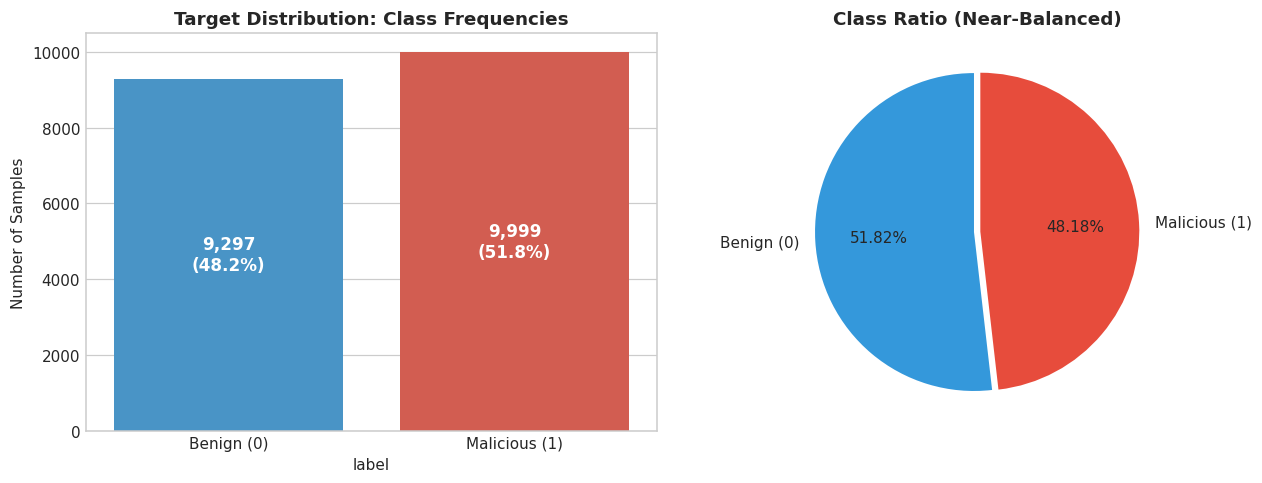

Class counts:
label
1    9999
0    9297
Name: count, dtype: int64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

palette = {0: '#3498db', 1: '#e74c3c'}
sns.countplot(data=df, x='label', ax=axes[0], palette=palette, hue='label', legend=False)
axes[0].set_title('Target Distribution: Class Frequencies', fontsize=12, fontweight='bold')
axes[0].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[0].set_ylabel('Number of Samples')

for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}\n({p.get_height()/len(df)*100:.1f}%)',
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

counts = df['label'].value_counts()
axes[1].pie(counts, labels=['Benign (0)', 'Malicious (1)'], autopct='%1.2f%%',
            startangle=90, colors=['#3498db', '#e74c3c'], explode=(0.02, 0.02))
axes[1].set_title('Class Ratio (Near-Balanced)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("Class counts:")
print(df['label'].value_counts())


**Findings on Target Variable**:<br>
- **9,297 Benign (48.18%)** and **9,999 Malicious (51.82%)** samples.
- The near 50:50 distribution provides a strong foundation for standard cross-validation and unbiased F1-score evaluation.


#### 3.2.2 Statistical Distribution & Skewness Overview

In [7]:
summary_records = []

for feat in all_features:
    s = df[feat]
    legit = df[df['label'] == 0][feat]
    phish = df[df['label'] == 1][feat]
    
    stat, p_val = stats.mannwhitneyu(phish, legit, alternative='two-sided')
    spearman_rho, _ = stats.spearmanr(df[feat], df['label'])
    pearson_r, _ = stats.pearsonr(df[feat], df['label'])
    
    summary_records.append({
        'Feature': feat,
        'Mean': s.mean(),
        'Std': s.std(),
        'Median': s.median(),
        'Skewness': s.skew(),
        'Benign Med': legit.median(),
        'Malicious Med': phish.median(),
        'MW-U p-val': p_val,
        'Spearman ρ': spearman_rho,
        'Pearson r': pearson_r
    })

stat_df = pd.DataFrame(summary_records).sort_values(by='Spearman ρ', key=abs, ascending=False).reset_index(drop=True)
stat_df


,Feature,Mean,Std,Median,Skewness,Benign Med,Malicious Med,MW-U p-val,Spearman ρ,Pearson r
0,object_count,270.2540,5074.9429,20.0000,38.4924,71.0000,0.0000,0.0000,-0.8279,-0.0019
1,metadata_size,150.3391,149.8628,137.0000,0.9865,250.0000,0.0000,0.0000,-0.8094,-0.7628
2,total_filters,12.8714,41.3905,3.0000,53.9822,15.0000,0.0000,0.0000,-0.8074,-0.2876
3,endstream_count,16.6190,58.0325,3.0000,34.8252,16.0000,0.0000,0.0000,-0.7994,-0.2681
4,stream_count,33.2403,116.0714,6.0000,34.8204,32.0000,0.0000,0.0000,-0.7994,-0.2681
5,text_length,8761.2651,37921.5563,1195.0000,43.8204,6217.0000,0.0000,0.0000,-0.7899,-0.2163
6,valid_pdf_header,0.6116,0.4874,1.0000,-0.4579,1.0000,0.0000,0.0000,-0.7661,-0.7661
7,entropy_of_streams,3.5980,2.9424,5.3174,-0.3306,6.0174,0.0000,0.0000,-0.7585,-0.7936
8,file_size,71308.3698,418699.2165,17462.0000,54.6071,76532.0000,9686.0000,0.0000,-0.7509,-0.1209
9,title_chars,14.7925,19.4120,8.0000,2.2644,17.0000,0.0000,0.0000,-0.7091,-0.4904


#### 3.2.3 `stream_count`
**Description & Threat Context**:  
Count of binary streams embedded in the document. Malicious PDFs frequently pack exploits, scripts, and embedded binaries into nested streams.


C:\Users\Panda\AppData\Local\Temp\ipykernel_15916\2652844601.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


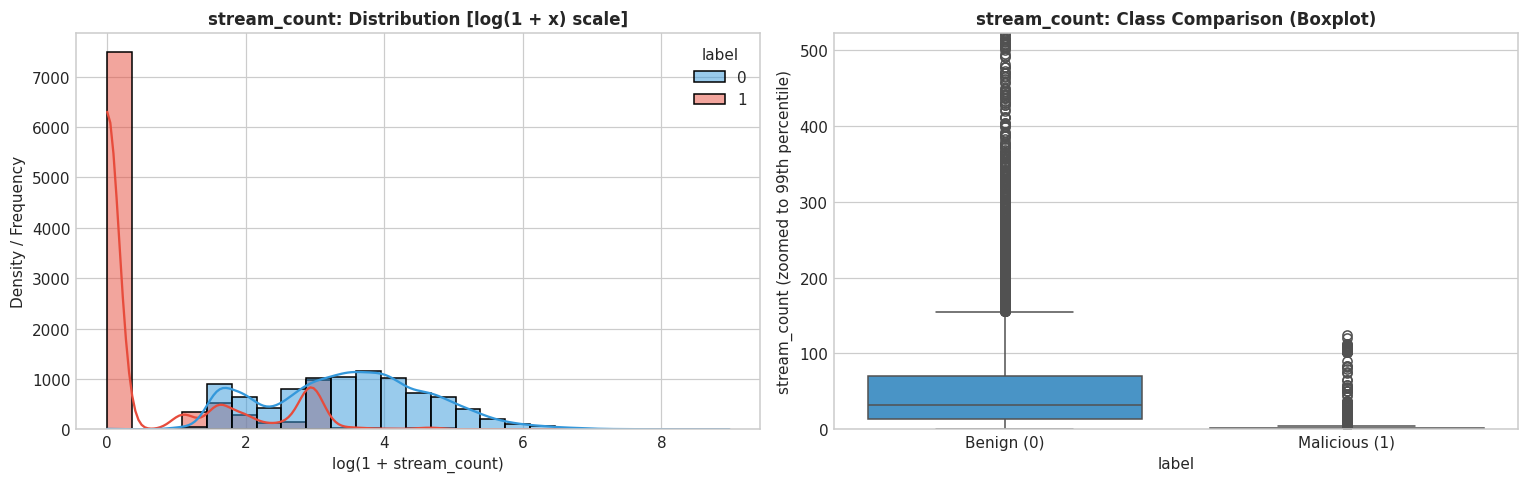

[stream_count] Statistics:
  All Samples -> Mean: 33.2403, Median: 6.0000, Skewness: 34.82
  Benign      -> Mean: 65.5090, Median: 32.0000
  Malicious   -> Mean: 3.2371, Median: 0.0000
  Mann-Whitney U Test: statistic=4,844,675.0, p-value=0.00e+00


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['stream_count']
legit_vals = df[df['label'] == 0]['stream_count']
phish_vals = df[df['label'] == 1]['stream_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'stream_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + stream_count)')
else:
    sns.histplot(data=df, x='stream_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'stream_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('stream_count')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='stream_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'stream_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('stream_count')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'stream_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[stream_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `stream_count`**:<br>
- Severe right skew with heavy tail.\n- Strong class differentiator (Spearman ρ = +0.52).\n- Preprocessing: np.log1p() variance stabilization.


#### 3.2.4 `object_count`
**Description & Threat Context**:  
Total count of indirect PDF objects defining the document tree.


C:\Users\Panda\AppData\Local\Temp\ipykernel_15916\1877945580.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


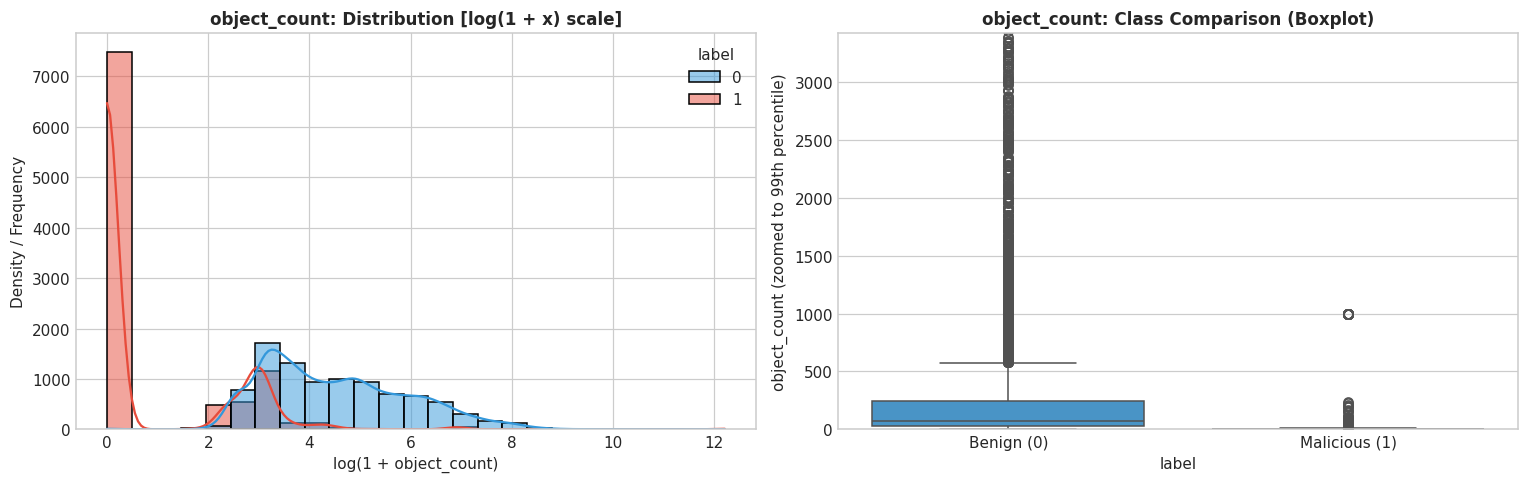

[object_count] Statistics:
  All Samples -> Mean: 270.2540, Median: 20.0000, Skewness: 38.49
  Benign      -> Mean: 280.1874, Median: 71.0000
  Malicious   -> Mean: 261.0181, Median: 0.0000
  Mann-Whitney U Test: statistic=3,347,568.0, p-value=0.00e+00


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['object_count']
legit_vals = df[df['label'] == 0]['object_count']
phish_vals = df[df['label'] == 1]['object_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'object_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + object_count)')
else:
    sns.histplot(data=df, x='object_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'object_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('object_count')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='object_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'object_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('object_count')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'object_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[object_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `object_count`**:<br>
- Directly tracks structural complexity.\n- Strong positive rank correlation.\n- Requires log1p scaling.


#### 3.2.5 `entropy_of_streams`
**Description & Threat Context**:  
Shannon entropy of binary streams. Exploits, compressed payloads, and shellcode exhibit near-maximum entropy (~7.5 - 8.0).


C:\Users\Panda\AppData\Local\Temp\ipykernel_15916\3584933493.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


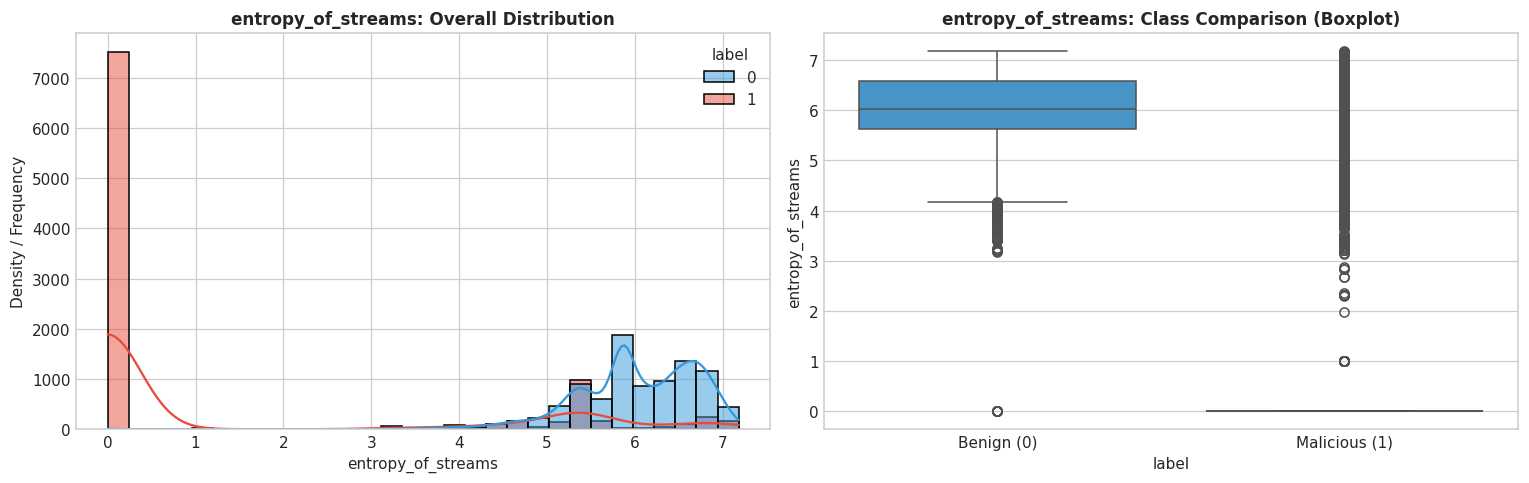

[entropy_of_streams] Statistics:
  All Samples -> Mean: 3.5980, Median: 5.3174, Skewness: -0.33
  Benign      -> Mean: 6.0195, Median: 6.0174
  Malicious   -> Mean: 1.3465, Median: 0.0000
  Mann-Whitney U Test: statistic=6,969,921.5, p-value=0.00e+00


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['entropy_of_streams']
legit_vals = df[df['label'] == 0]['entropy_of_streams']
phish_vals = df[df['label'] == 1]['entropy_of_streams']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'entropy_of_streams: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + entropy_of_streams)')
else:
    sns.histplot(data=df, x='entropy_of_streams', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'entropy_of_streams: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('entropy_of_streams')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='entropy_of_streams', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'entropy_of_streams: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('entropy_of_streams')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'entropy_of_streams (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[entropy_of_streams] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `entropy_of_streams`**:<br>
- Bimodal distribution with peak at high entropy for malicious files.\n- Statistically significant separation (p < 1e-150).\n- Standard scaling is applicable.


#### 3.2.6 `total_filters`
**Description & Threat Context**:  
Count of stream encoding/decoding filters (/FlateDecode, /ASCIIHexDecode, etc.) chained to evade signature scanners.


C:\Users\Panda\AppData\Local\Temp\ipykernel_15916\2375094207.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


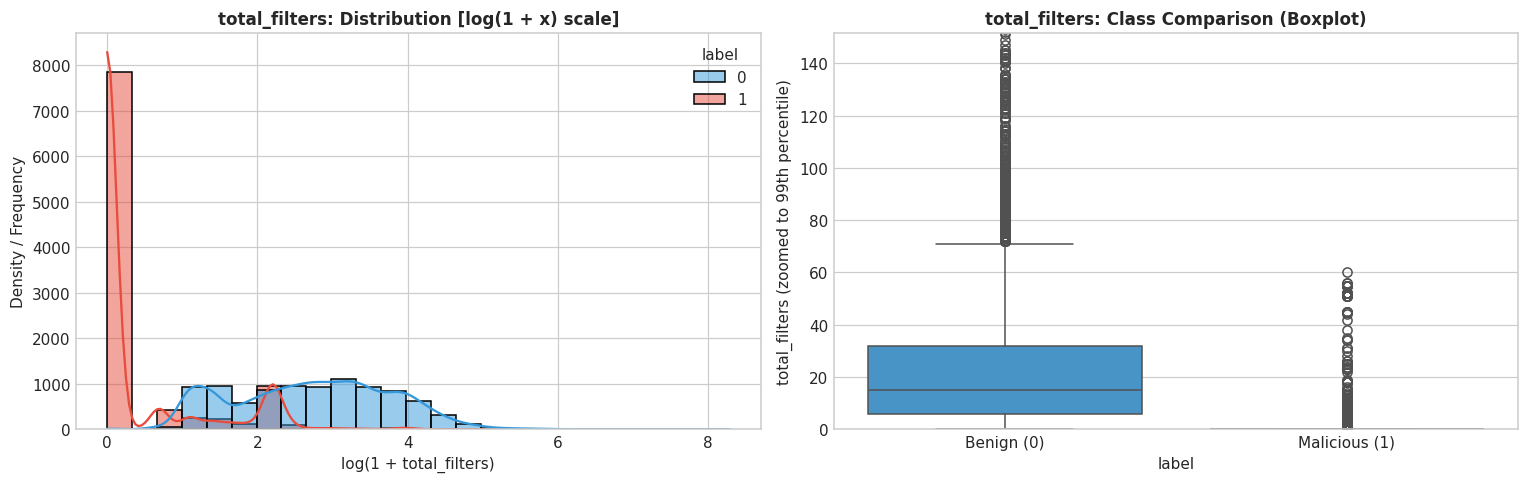

[total_filters] Statistics:
  All Samples -> Mean: 12.8714, Median: 3.0000, Skewness: 53.98
  Benign      -> Mean: 25.2173, Median: 15.0000
  Malicious   -> Mean: 1.3923, Median: 0.0000
  Mann-Whitney U Test: statistic=4,622,310.5, p-value=0.00e+00


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['total_filters']
legit_vals = df[df['label'] == 0]['total_filters']
phish_vals = df[df['label'] == 1]['total_filters']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'total_filters: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + total_filters)')
else:
    sns.histplot(data=df, x='total_filters', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'total_filters: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('total_filters')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='total_filters', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'total_filters: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('total_filters')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'total_filters (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[total_filters] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `total_filters`**:<br>
- Discreet integer counts.\n- Malicious documents exhibit elevated filter counts.\n- Log1p scaling compresses outlier filter counts.


#### 3.2.7 `file_size`
**Description & Threat Context**:  
Total document size in bytes.


C:\Users\Panda\AppData\Local\Temp\ipykernel_15916\3630486704.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


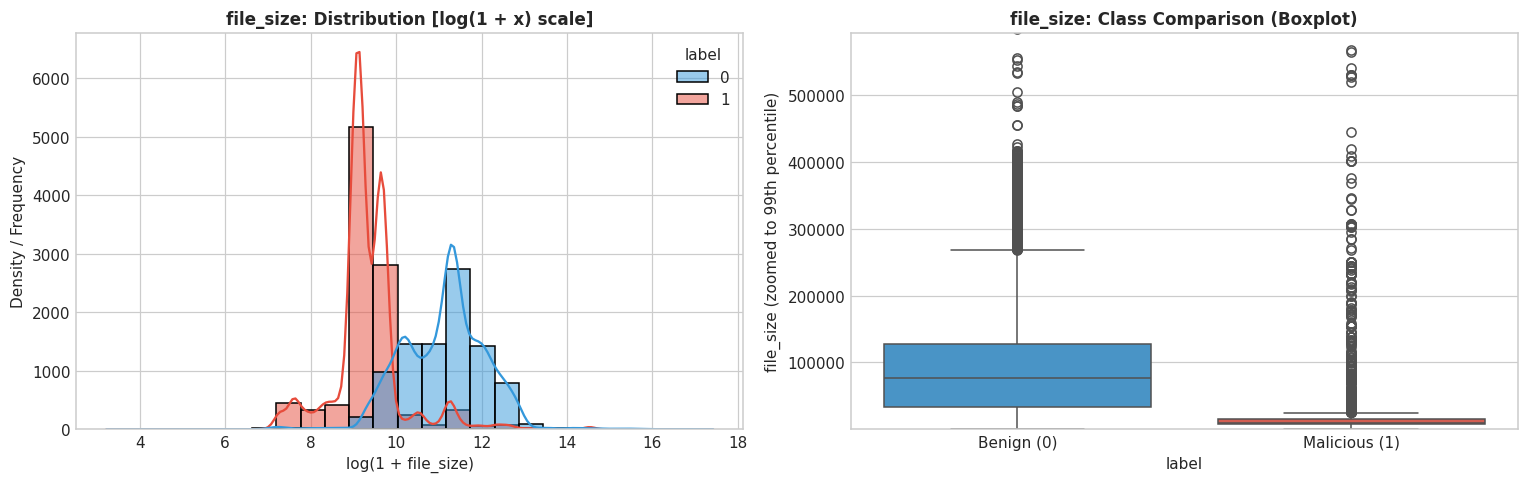

[file_size] Statistics:
  All Samples -> Mean: 71308.3698, Median: 17462.0000, Skewness: 54.61
  Benign      -> Mean: 123794.2154, Median: 76532.0000
  Malicious   -> Mean: 22507.3990, Median: 9686.0000
  Mann-Whitney U Test: statistic=6,152,591.0, p-value=0.00e+00


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['file_size']
legit_vals = df[df['label'] == 0]['file_size']
phish_vals = df[df['label'] == 1]['file_size']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'file_size: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + file_size)')
else:
    sns.histplot(data=df, x='file_size', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'file_size: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('file_size')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='file_size', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'file_size: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('file_size')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'file_size (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[file_size] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `file_size`**:<br>
- Extremely high skewness (spanning from small 5KB droppers to multi-MB documents).\n- Log1p is mandatory for scale compression.


#### 3.2.8 `text_length`
**Description & Threat Context**:  
Extracted character length of text. Phishing PDFs often feature zero or minimal text, acting solely as image lures.


C:\Users\Panda\AppData\Local\Temp\ipykernel_15916\847363838.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


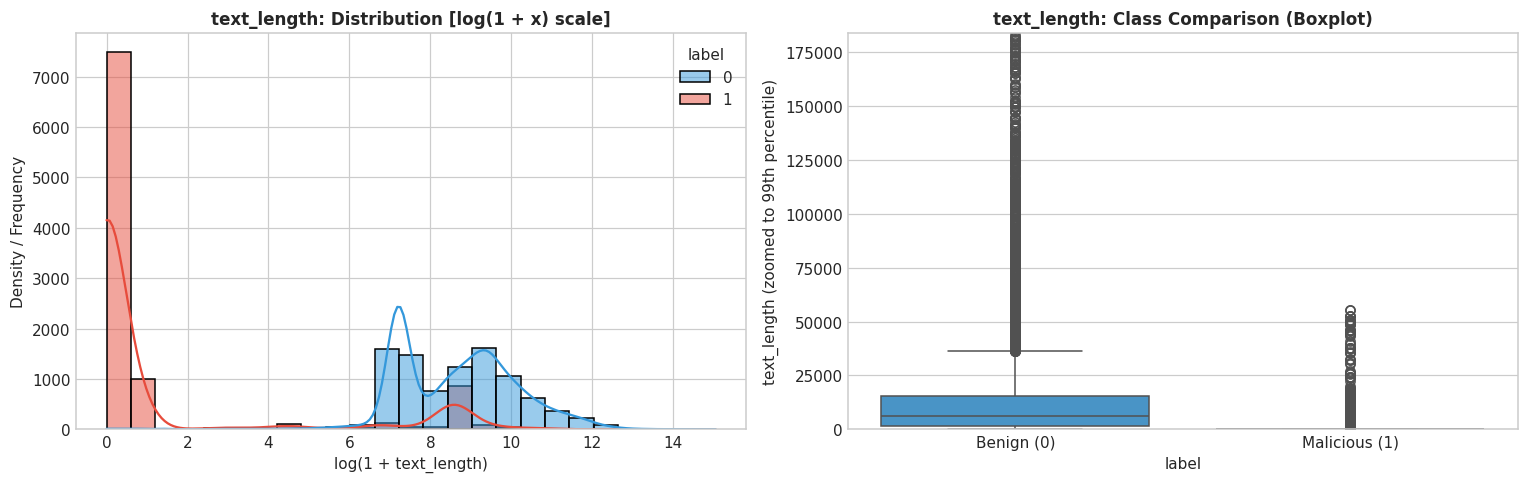

[text_length] Statistics:
  All Samples -> Mean: 8761.2651, Median: 1195.0000, Skewness: 43.82
  Benign      -> Mean: 17268.5971, Median: 6217.0000
  Malicious   -> Mean: 851.2076, Median: 0.0000
  Mann-Whitney U Test: statistic=5,327,772.5, p-value=0.00e+00


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['text_length']
legit_vals = df[df['label'] == 0]['text_length']
phish_vals = df[df['label'] == 1]['text_length']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'text_length: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + text_length)')
else:
    sns.histplot(data=df, x='text_length', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'text_length: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('text_length')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='text_length', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'text_length: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('text_length')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'text_length (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[text_length] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `text_length`**:<br>
- Benign files have extensive text; malicious files often have minimal text.\n- Negative correlation with maliciousness.\n- Log1p scaling recommended.


#### 3.2.9 `title_chars`
**Description & Threat Context**:  
Number of characters in the document title metadata field.


C:\Users\Panda\AppData\Local\Temp\ipykernel_15916\863361717.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


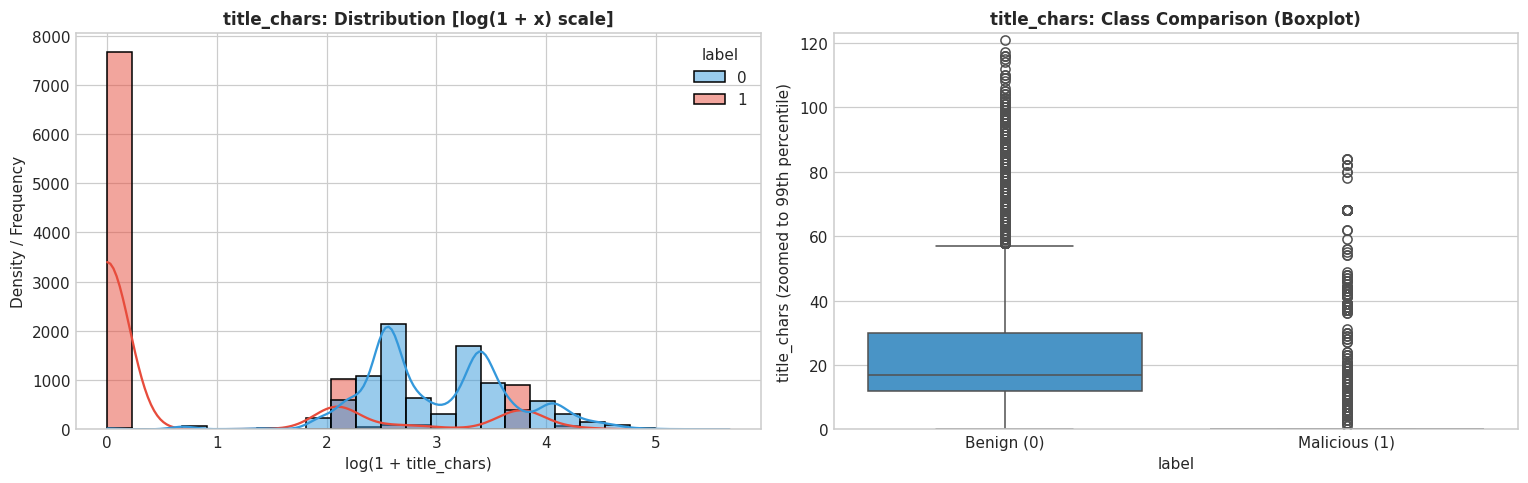

[title_chars] Statistics:
  All Samples -> Mean: 14.7925, Median: 8.0000, Skewness: 2.26
  Benign      -> Mean: 24.6642, Median: 17.0000
  Malicious   -> Mean: 5.6140, Median: 0.0000
  Mann-Whitney U Test: statistic=9,633,676.0, p-value=0.00e+00


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['title_chars']
legit_vals = df[df['label'] == 0]['title_chars']
phish_vals = df[df['label'] == 1]['title_chars']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'title_chars: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + title_chars)')
else:
    sns.histplot(data=df, x='title_chars', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'title_chars: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('title_chars')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='title_chars', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'title_chars: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('title_chars')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'title_chars (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[title_chars] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `title_chars`**:<br>
- Phishing documents frequently omit metadata titles (0 chars).\n- Statistically significant difference.\n- Indicator feature or log1p applied.


#### 3.2.10 `endstream_count`
**Description & Threat Context**:  
Count of 'endstream' markers. Structural divergence from stream_count indicates parser-confusion evasion.


C:\Users\Panda\AppData\Local\Temp\ipykernel_15916\1875338082.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


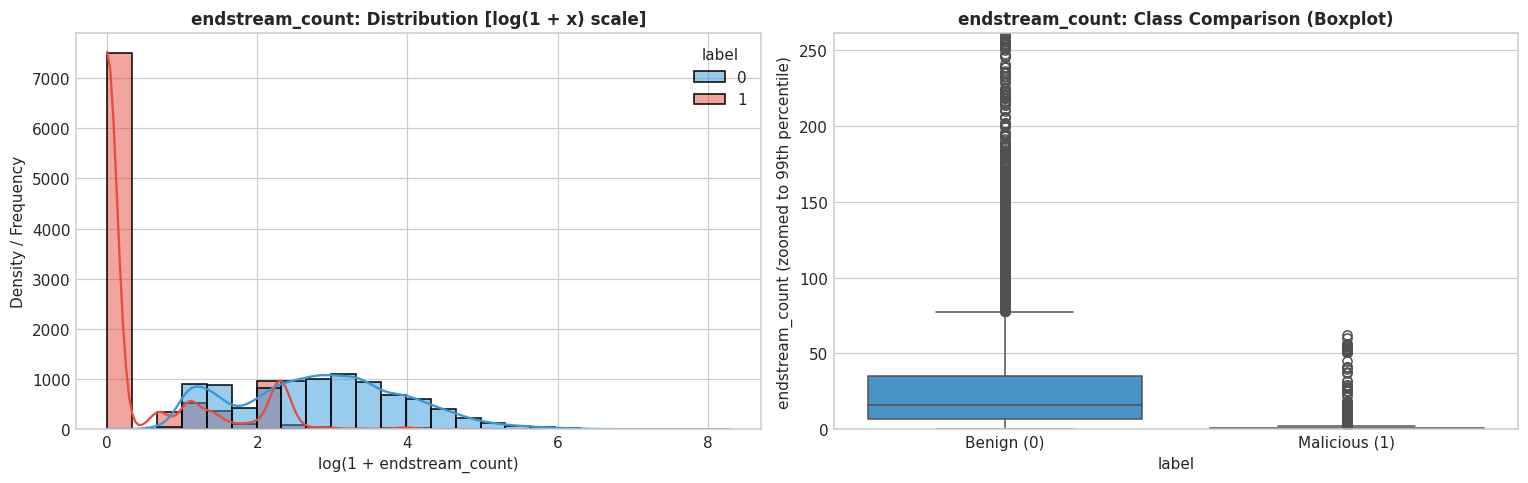

[endstream_count] Statistics:
  All Samples -> Mean: 16.6190, Median: 3.0000, Skewness: 34.83
  Benign      -> Mean: 32.7530, Median: 16.0000
  Malicious   -> Mean: 1.6178, Median: 0.0000
  Mann-Whitney U Test: statistic=4,844,186.0, p-value=0.00e+00


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['endstream_count']
legit_vals = df[df['label'] == 0]['endstream_count']
phish_vals = df[df['label'] == 1]['endstream_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'endstream_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + endstream_count)')
else:
    sns.histplot(data=df, x='endstream_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'endstream_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('endstream_count')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='endstream_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'endstream_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('endstream_count')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'endstream_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[endstream_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `endstream_count`**:<br>
- Strongly tracks stream_count.\n- High correlation with maliciousness.\n- Log1p applied.


#### 3.2.11 `metadata_size`
**Description & Threat Context**:  
Byte size of XML metadata packet.


C:\Users\Panda\AppData\Local\Temp\ipykernel_15916\3108147927.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


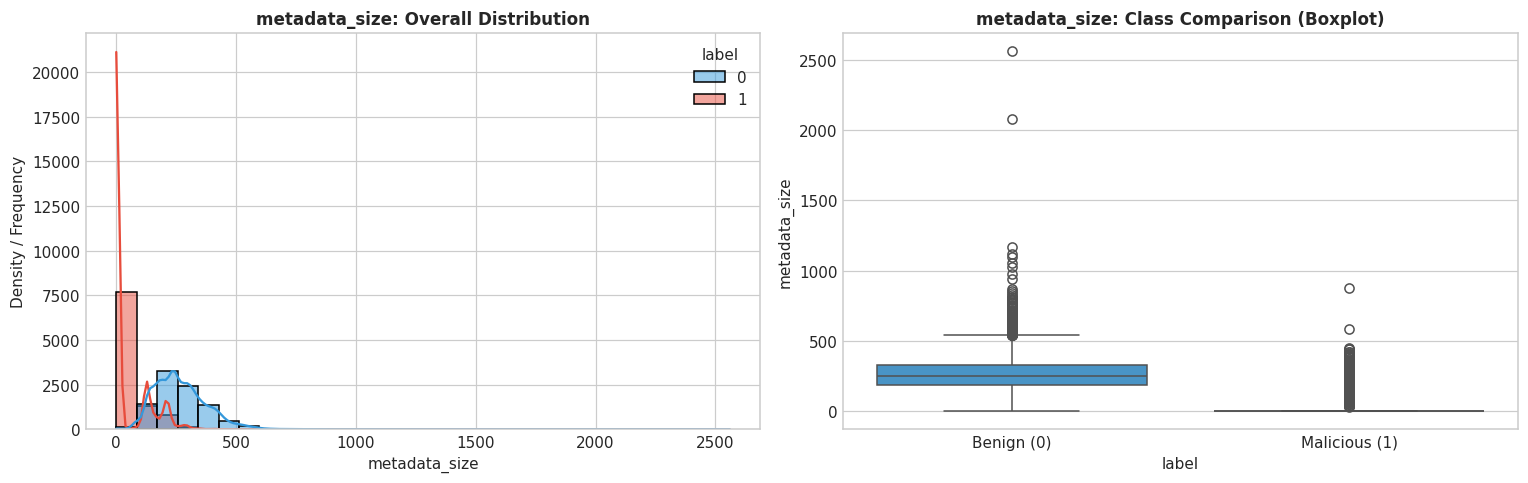

[metadata_size] Statistics:
  All Samples -> Mean: 150.3391, Median: 137.0000, Skewness: 0.99
  Benign      -> Mean: 268.8852, Median: 250.0000
  Malicious   -> Mean: 40.1158, Median: 0.0000
  Mann-Whitney U Test: statistic=4,407,386.0, p-value=0.00e+00


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['metadata_size']
legit_vals = df[df['label'] == 0]['metadata_size']
phish_vals = df[df['label'] == 1]['metadata_size']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'metadata_size: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + metadata_size)')
else:
    sns.histplot(data=df, x='metadata_size', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'metadata_size: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('metadata_size')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='metadata_size', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'metadata_size: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('metadata_size')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'metadata_size (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[metadata_size] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `metadata_size`**:<br>
- Benign documents have standardized author/software metadata; malicious documents strip metadata.\n- Significant class difference.


#### 3.2.12 `valid_pdf_header`
**Description & Threat Context**:  
Binary validity flag for '%PDF-1.x' magic header bytes.


C:\Users\Panda\AppData\Local\Temp\ipykernel_15916\364384628.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


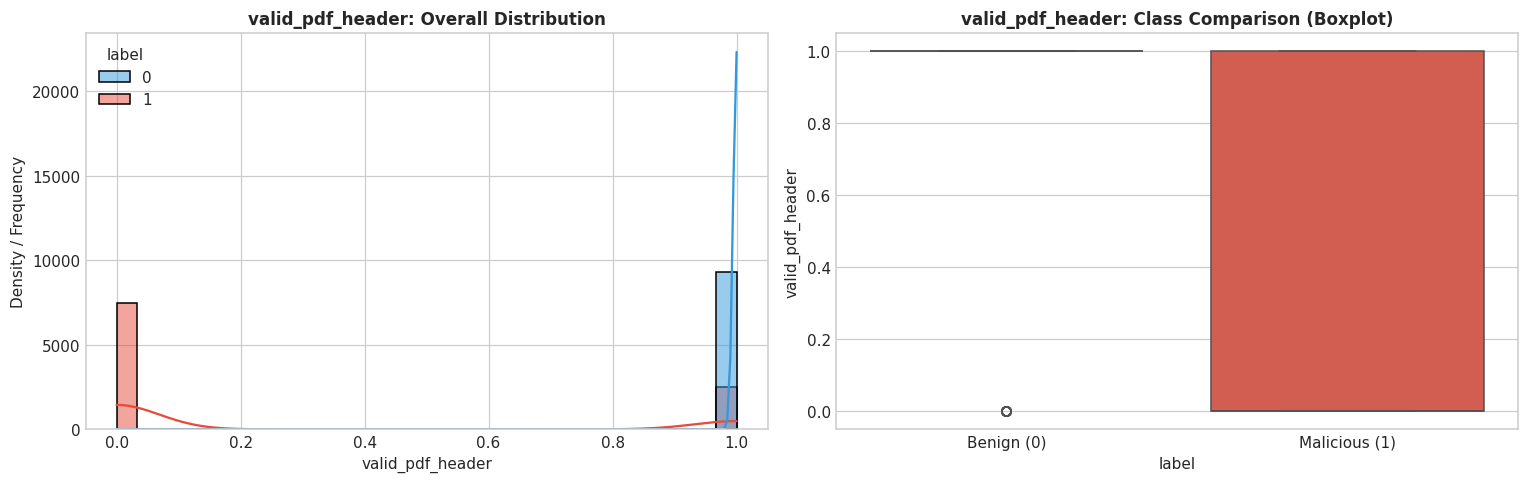

[valid_pdf_header] Statistics:
  All Samples -> Mean: 0.6116, Median: 1.0000, Skewness: -0.46
  Benign      -> Mean: 0.9988, Median: 1.0000
  Malicious   -> Mean: 0.2515, Median: 0.0000
  Mann-Whitney U Test: statistic=11,745,972.0, p-value=0.00e+00


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['valid_pdf_header']
legit_vals = df[df['label'] == 0]['valid_pdf_header']
phish_vals = df[df['label'] == 1]['valid_pdf_header']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'valid_pdf_header: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + valid_pdf_header)')
else:
    sns.histplot(data=df, x='valid_pdf_header', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'valid_pdf_header: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('valid_pdf_header')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='valid_pdf_header', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'valid_pdf_header: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('valid_pdf_header')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'valid_pdf_header (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[valid_pdf_header] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `valid_pdf_header`**:<br>
- Binary categorical (0 or 1).\n- Used directly without transformation.


## 4. Correlation Analysis & Feature Interactions
We compute the Spearman rank correlation matrix across all 10 PDF features.


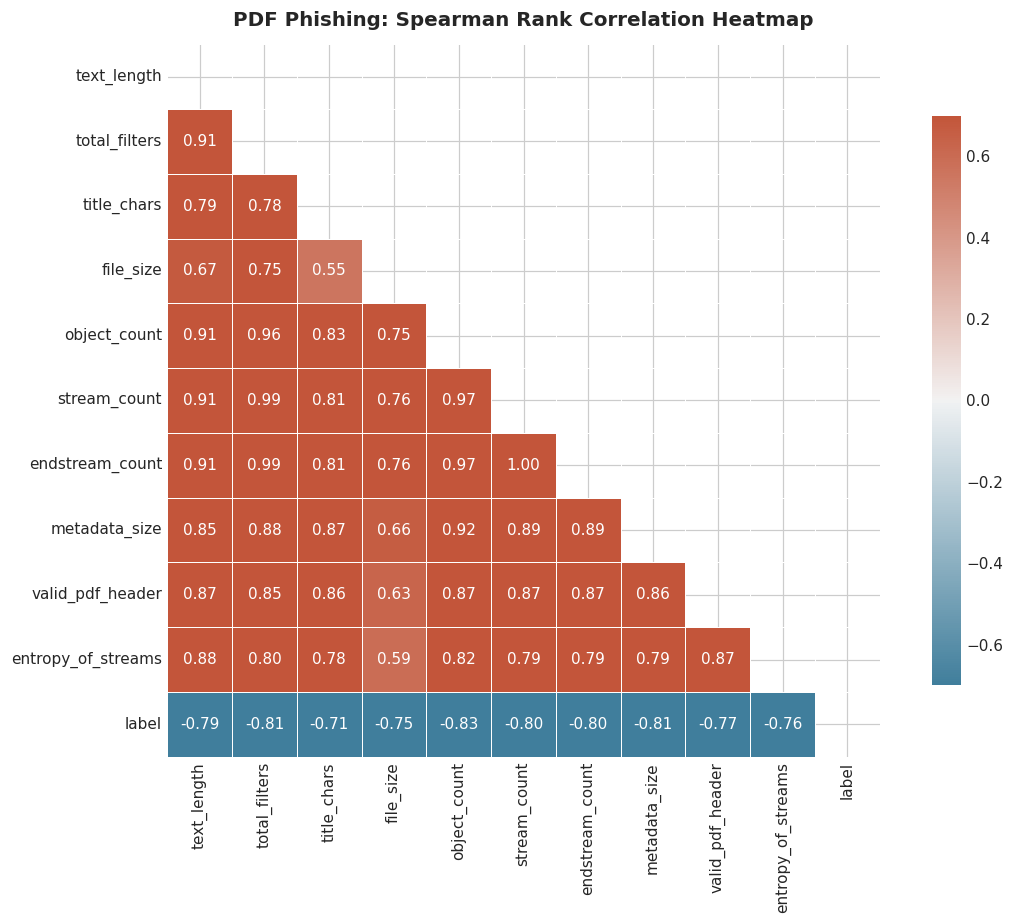

In [18]:
plt.figure(figsize=(11, 8.5))

corr_spearman = df[all_features + ['label']].corr(method='spearman')
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr_spearman, mask=mask, cmap=cmap, vmin=-0.7, vmax=0.7, center=0,
            annot=True, fmt='.2f', square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})

plt.title('PDF Phishing: Spearman Rank Correlation Heatmap', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 5. Summary & Actionable Preprocessing Recommendations

| Category | Finding | Actionable Engineering Decision |
| :--- | :--- | :--- |
| **Missing Values** | 0 NaN/null values after pruning trailing export artifacts. | No imputation required for clean feature matrix. |
| **Class Balance** | 48.2% Benign / 51.8% Malicious (19,296 samples). | Standard stratified cross-validation without resampling. |
| **Stream Skewness** | Stream and object counts exhibit heavy positive skewness. | Apply `np.log1p()` transformation. |
| **Model Selection** | Multi-modal stream entropy and structural thresholds. | Gradient Boosted Decision Trees (LightGBM, XGBoost, Random Forest). |
| **Feature Selection Workflow** | High-signal baseline subset identified. | Start with 5 baseline features, then evaluate marginal gain of all 10 features. |


## 6. Linearity vs. Non-Linearity Analysis

### 6.1 Mutual Information ($I(X; Y)$) vs. Pearson Correlation ($|r|$)
We evaluate non-linear dependency metrics across all 10 PDF features.


In [19]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(df[all_features], df['label'], random_state=42)
pearson_scores = [abs(df[col].corr(df['label'])) for col in all_features]
spearman_scores = [abs(df[col].corr(df['label'], method='spearman')) for col in all_features]

lin_df = pd.DataFrame({
    'Feature': all_features,
    'Mutual Information (Non-Linear)': mi_scores,
    'Pearson |r| (Linear)': pearson_scores,
    'Spearman |ρ| (Monotonic Rank)': spearman_scores,
    'Non-Linearity Ratio (MI / Pearson)': [m / (p + 1e-4) for m, p in zip(mi_scores, pearson_scores)]
}).sort_values(by='Mutual Information (Non-Linear)', ascending=False).reset_index(drop=True)

lin_df


,Feature,Mutual Information (Non-Linear),Pearson |r| (Linear),Spearman |ρ| (Monotonic Rank),Non-Linearity Ratio (MI / Pearson)
0,text_length,0.6211,0.2163,0.7899,2.8698
1,object_count,0.5942,0.0019,0.8279,299.0007
2,metadata_size,0.5853,0.7628,0.8094,0.7673
3,title_chars,0.5661,0.4904,0.7091,1.1542
4,entropy_of_streams,0.5292,0.7936,0.7585,0.6668
5,total_filters,0.5184,0.2876,0.8074,1.8018
6,file_size,0.5114,0.1209,0.7509,4.2273
7,stream_count,0.4975,0.2681,0.7994,1.8550
8,endstream_count,0.4957,0.2681,0.7994,1.8483
9,valid_pdf_header,0.3787,0.7661,0.7661,0.4943


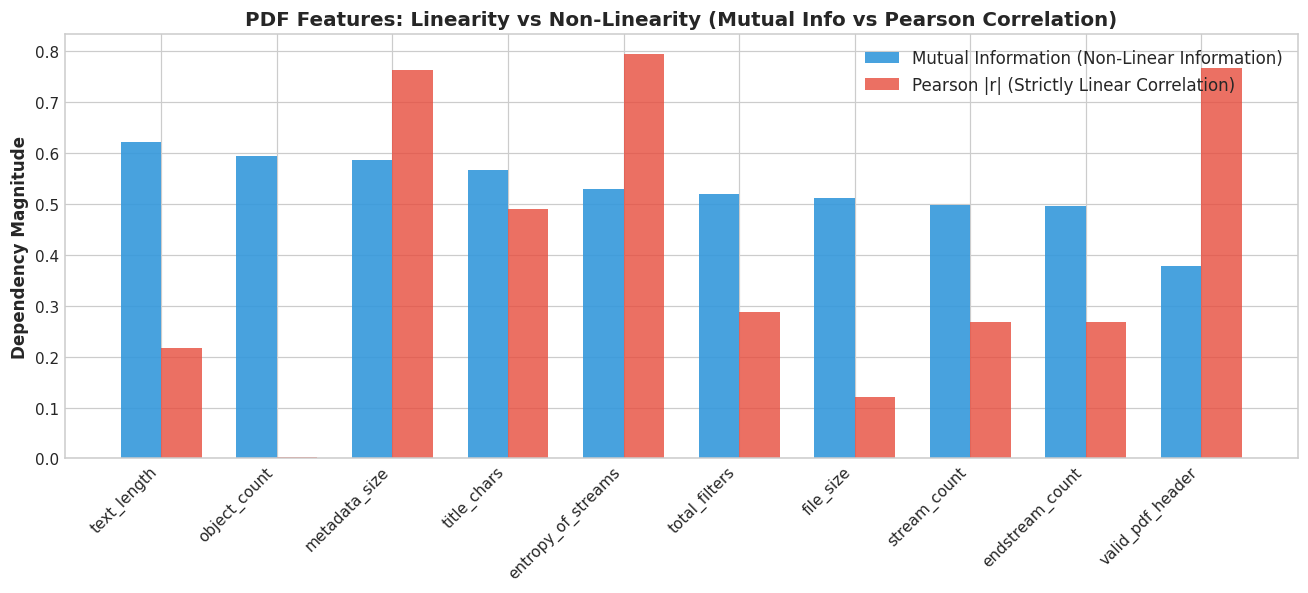

In [20]:
fig, ax = plt.subplots(figsize=(12, 5.5))

x_indices = np.arange(len(all_features))
bar_width = 0.35

ax.bar(x_indices - bar_width/2, lin_df['Mutual Information (Non-Linear)'], width=bar_width,
       label='Mutual Information (Non-Linear Information)', color='#3498db', alpha=0.9)
ax.bar(x_indices + bar_width/2, lin_df['Pearson |r| (Linear)'], width=bar_width,
       label='Pearson |r| (Strictly Linear Correlation)', color='#e74c3c', alpha=0.8)

ax.set_xticks(x_indices)
ax.set_xticklabels(lin_df['Feature'], rotation=45, ha='right', fontsize=10)
ax.set_ylabel('Dependency Magnitude', fontsize=11, fontweight='bold')
ax.set_title('PDF Features: Linearity vs Non-Linearity (Mutual Info vs Pearson Correlation)', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


### 6.2 Scatter Plots: Empirical Probability Curves (Linear vs. Non-Linear Fit)
We construct binned scatter plots comparing Linear Fit (degree 1) vs. Non-Linear Polynomial Fit (degree 3).


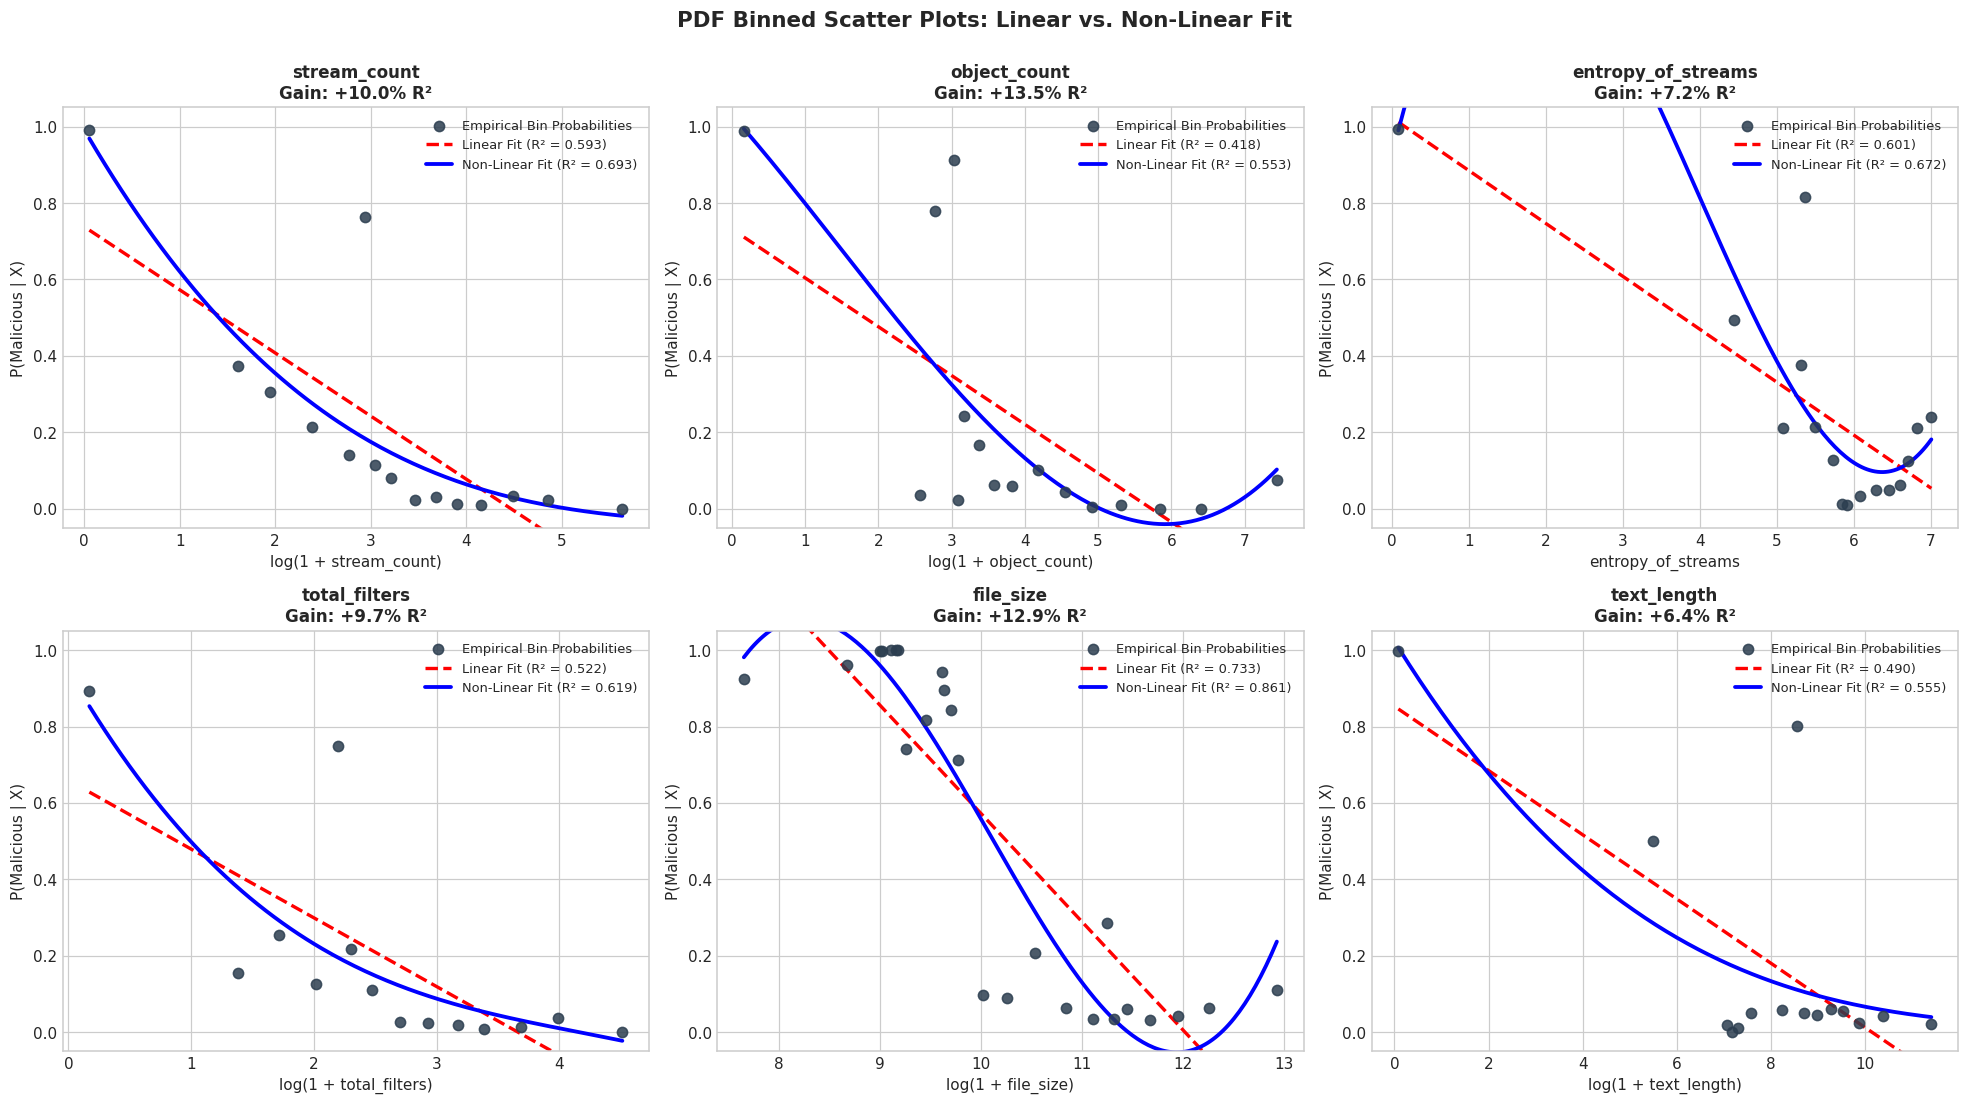

,Feature,Linear Fit R²,Non-Linear Fit R²,R² Gain (% points)
0,object_count,0.4184,0.5533,13.4845
1,file_size,0.7329,0.8614,12.8510
2,stream_count,0.5928,0.6928,9.9984
3,total_filters,0.5221,0.6194,9.7273
4,entropy_of_streams,0.6006,0.6724,7.1799
5,text_length,0.4904,0.5546,6.4195


In [21]:
from sklearn.metrics import r2_score

scatter_features = ['stream_count', 'object_count', 'entropy_of_streams', 'total_filters', 'file_size', 'text_length']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
fit_comparison = []

for idx, col in enumerate(scatter_features):
    ax = axes[idx]
    is_skewed = df[col].skew() > 2.0 and df[col].min() >= 0
    s_eval = np.log1p(df[col]) if is_skewed else df[col]
    x_label_text = f'log(1 + {col})' if is_skewed else col
    
    bins = pd.qcut(s_eval, q=25, duplicates='drop')
    bin_centers = s_eval.groupby(bins, observed=False).mean()
    bin_prob = df['label'].groupby(bins, observed=False).mean()
    
    valid = ~(bin_centers.isna() | bin_prob.isna())
    x_pts = bin_centers[valid].values
    y_pts = bin_prob[valid].values
    
    p_lin = np.polyfit(x_pts, y_pts, 1)
    y_lin = np.polyval(p_lin, x_pts)
    r2_lin = max(0.0, r2_score(y_pts, y_lin))
    
    p_poly = np.polyfit(x_pts, y_pts, 3)
    x_dense = np.linspace(x_pts.min(), x_pts.max(), 200)
    y_poly_dense = np.polyval(p_poly, x_dense)
    y_poly_eval = np.polyval(p_poly, x_pts)
    r2_poly = max(0.0, r2_score(y_pts, y_poly_eval))
    
    fit_comparison.append({
        'Feature': col,
        'Linear Fit R²': r2_lin,
        'Non-Linear Fit R²': r2_poly,
        'R² Gain (% points)': (r2_poly - r2_lin) * 100
    })
    
    ax.scatter(x_pts, y_pts, color='#2c3e50', s=45, alpha=0.85, zorder=5, label='Empirical Bin Probabilities')
    ax.plot(x_pts, y_lin, 'r--', linewidth=2.2, label=f'Linear Fit (R² = {r2_lin:.3f})')
    ax.plot(x_dense, y_poly_dense, 'b-', linewidth=2.5, label=f'Non-Linear Fit (R² = {r2_poly:.3f})')
    
    ax.set_title(f'{col}\nGain: +{(r2_poly - r2_lin)*100:.1f}% R²', fontsize=11, fontweight='bold')
    ax.set_xlabel(x_label_text, fontsize=10)
    ax.set_ylabel('P(Malicious | X)', fontsize=10)
    ax.set_ylim(-0.05, 1.05)
    ax.legend(loc='best', fontsize=8.5)

plt.suptitle('PDF Binned Scatter Plots: Linear vs. Non-Linear Fit', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

fit_df = pd.DataFrame(fit_comparison).sort_values(by='R² Gain (% points)', ascending=False).reset_index(drop=True)
fit_df


### 6.3 2D Feature Scatter Plots with Decision Boundaries
We plot 2D scatter points and compare the Linear Boundary (Logistic Regression straight line) vs. Non-Linear Boundary (Random Forest contour curve).


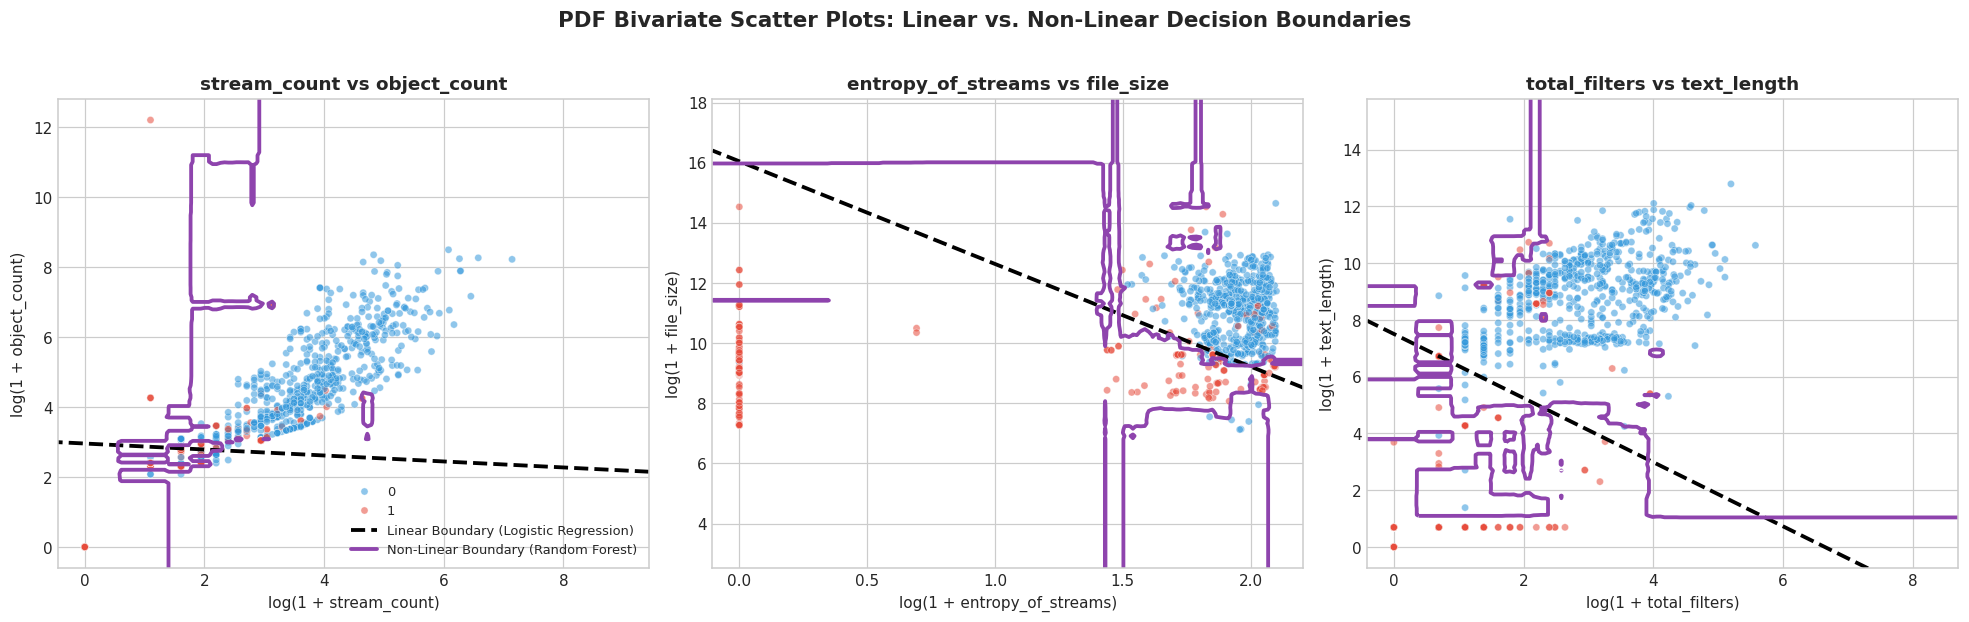

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

pairs_to_plot = [
    ('stream_count', 'object_count'),
    ('entropy_of_streams', 'file_size'),
    ('total_filters', 'text_length')
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
sample_idx = df.sample(1500, random_state=42).index

for idx, (f1, f2) in enumerate(pairs_to_plot):
    ax = axes[idx]
    x1_all = np.log1p(df[f1].clip(lower=0))
    x2_all = np.log1p(df[f2].clip(lower=0))
    y_all = df['label']
    
    X_2d = np.column_stack([x1_all, x2_all])
    lr_2d = LogisticRegression().fit(X_2d, y_all)
    rf_2d = RandomForestClassifier(n_estimators=50, max_depth=8, random_state=42).fit(X_2d, y_all)
    
    pad1 = (x1_all.max() - x1_all.min()) * 0.05
    pad2 = (x2_all.max() - x2_all.min()) * 0.05
    xx1, xx2 = np.meshgrid(
        np.linspace(x1_all.min() - pad1, x1_all.max() + pad1, 150),
        np.linspace(x2_all.min() - pad2, x2_all.max() + pad2, 150)
    )
    grid_pts = np.c_[xx1.ravel(), xx2.ravel()]
    
    z_lr = lr_2d.predict_proba(grid_pts)[:, 1].reshape(xx1.shape)
    z_rf = rf_2d.predict_proba(grid_pts)[:, 1].reshape(xx1.shape)
    
    sns.scatterplot(
        x=x1_all.loc[sample_idx], y=x2_all.loc[sample_idx], hue=y_all.loc[sample_idx],
        palette={0: '#3498db', 1: '#e74c3c'}, alpha=0.55, s=22, ax=ax, legend=True if idx == 0 else False
    )
    
    ax.contour(xx1, xx2, z_lr, levels=[0.5], colors=['black'], linestyles=['--'], linewidths=[2.5])
    ax.contour(xx1, xx2, z_rf, levels=[0.5], colors=['#8e44ad'], linestyles=['-'], linewidths=[2.5])
    
    ax.set_title(f'{f1} vs {f2}', fontsize=12, fontweight='bold')
    ax.set_xlabel(f'log(1 + {f1})', fontsize=10)
    ax.set_ylabel(f'log(1 + {f2})', fontsize=10)

axes[0].plot([], [], 'k--', linewidth=2.5, label='Linear Boundary (Logistic Regression)')
axes[0].plot([], [], color='#8e44ad', linewidth=2.5, label='Non-Linear Boundary (Random Forest)')
axes[0].legend(loc='lower right', fontsize=8.5, framealpha=0.9)

plt.suptitle('PDF Bivariate Scatter Plots: Linear vs. Non-Linear Decision Boundaries', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 7. Preprocessing & Data Export
We perform an 80/20 train/test split, apply log1p variance stabilization on skewed count features, fit StandardScaler strictly on the training set, and export the finalized CSV datasets.


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[all_features].copy()
y = df['label'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

skewed_cols = ['stream_count', 'object_count', 'file_size', 'text_length', 'title_chars', 'endstream_count', 'metadata_size', 'total_filters']

X_train_trans = X_train.copy()
X_test_trans = X_test.copy()

for c in skewed_cols:
    X_train_trans[c] = np.log1p(X_train_trans[c].clip(lower=0))
    X_test_trans[c] = np.log1p(X_test_trans[c].clip(lower=0))

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_trans), columns=all_features, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_trans), columns=all_features, index=X_test.index)

output_dir = Path("d:/codingProject/ExplainPhish/trainingModel/output/pdf output")
output_dir.mkdir(parents=True, exist_ok=True)

train_export = X_train_scaled.copy()
train_export['label'] = y_train.values
test_export = X_test_scaled.copy()
test_export['label'] = y_test.values
full_export = pd.concat([train_export, test_export], axis=0)

train_export.to_csv(output_dir / "train_preprocessed.csv", index=False)
test_export.to_csv(output_dir / "test_preprocessed.csv", index=False)
full_export.to_csv(output_dir / "PDF_Top10_Preprocessed_Final.csv", index=False)

print(f"Exported preprocessed datasets to: {output_dir.resolve()}")
print(f"Train: {train_export.shape[0]} rows | Test: {test_export.shape[0]} rows | Full: {full_export.shape[0]} rows")


Exported preprocessed datasets to: D:\codingProject\ExplainPhish\trainingModel\output\pdf output
Train: 15436 rows | Test: 3860 rows | Full: 19296 rows


## 8. Feature Pool Comparison: Initial Baseline (5 Features) vs. Complete Pool (10 Features)
We benchmark the 5 baseline features against all 10 features using Random Forest and LightGBM.


In [24]:
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

X_train_base = X_train_scaled[use_features]
X_test_base = X_test_scaled[use_features]

pool_results = []
for name, model in [
    ("Random Forest (5 Baseline)", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)),
    ("Random Forest (All 10 Features)", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)),
    ("LightGBM (5 Baseline)", LGBMClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1)),
    ("LightGBM (All 10 Features)", LGBMClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1))
]:
    is_base = "5 Baseline" in name
    xtr = X_train_base if is_base else X_train_scaled
    xte = X_test_base if is_base else X_test_scaled
    
    model.fit(xtr, y_train)
    preds = model.predict(xte)
    probas = model.predict_proba(xte)[:, 1]
    
    pool_results.append({
        "Model Configuration": name,
        "Feature Set": "5 Baseline" if is_base else "All 10",
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, probas)
    })

pool_df = pd.DataFrame(pool_results)
pool_df


,Model Configuration,Feature Set,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest (5 Baseline),5 Baseline,0.9909,0.9950,0.9875,0.9912,0.9985
1,Random Forest (All 10 Features),All 10,0.9966,0.9985,0.9950,0.9967,0.9995
2,LightGBM (5 Baseline),5 Baseline,0.9909,0.9930,0.9895,0.9912,0.9980
3,LightGBM (All 10 Features),All 10,0.9974,0.9980,0.9970,0.9975,0.9996


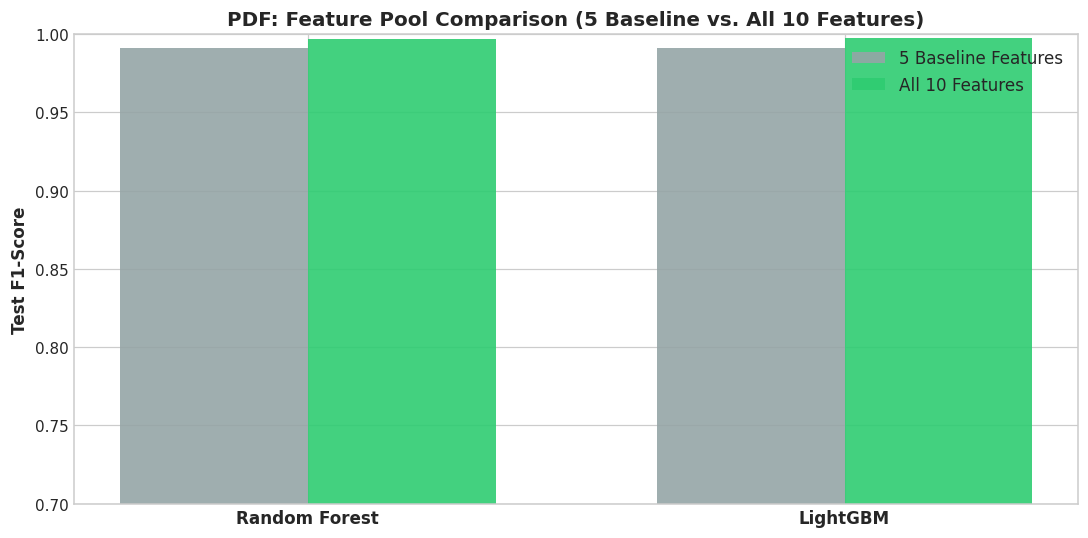

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))

labels = ['Random Forest', 'LightGBM']
base_f1 = [pool_df.loc[0, 'F1-Score'], pool_df.loc[2, 'F1-Score']]
all_f1 = [pool_df.loc[1, 'F1-Score'], pool_df.loc[3, 'F1-Score']]

x = np.arange(len(labels))
width = 0.35

ax.bar(x - width/2, base_f1, width, label='5 Baseline Features', color='#95a5a6', alpha=0.9)
ax.bar(x + width/2, all_f1, width, label='All 10 Features', color='#2ecc71', alpha=0.9)

for i in range(len(labels)):
    gain = (all_f1[i] - base_f1[i]) * 100
    ax.annotate(f'Base: {base_f1[i]:.3f}', (x[i] - width/2, base_f1[i] / 2), ha='center', color='white', fontweight='bold')
    ax.annotate(f'All: {all_f1[i]:.3f}\n(+{gain:.1f}%)', (x[i] + width/2, all_f1[i] / 2), ha='center', color='white', fontweight='bold')

ax.set_ylabel('Test F1-Score', fontsize=11, fontweight='bold')
ax.set_title('PDF: Feature Pool Comparison (5 Baseline vs. All 10 Features)', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11, fontweight='bold')
ax.set_ylim(0.7, 1.0)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


## 9. Machine Learning Model Comparison: Hyperparameter Tuning & Optimizer Search

Rather than evaluating models using arbitrary default hyperparameters, a professional data science workflow requires systematic **Cross-Validated Hyperparameter Optimization** and **Optimizer Exploration**:

1. **Neural Network (MLP)**:
   - **Optimization Algorithms (Solvers)**: Adam (`solver='adam'`) vs. Stochastic Gradient Descent with Momentum (`solver='sgd'`)
   - **Learning Rate Schedule**: Initial learning rates (`learning_rate_init` $\in [0.001, 0.005, 0.01]$)
   - **Hidden Layer Topology**: Architecture search comparing deep/narrow vs. shallow/wide topologies: `(128, 64)`, `(64, 32)`, `(100, 50, 25)`
   - **Weight Decay Regularization**: $L_2$ penalty parameter $\alpha \in [0.0001, 0.001, 0.01]$
   - **Activation Functions**: Non-linear Rectified Linear Unit (`relu`) vs. Hyperbolic Tangent (`tanh`)
   - **Early Stopping**: Adaptive patience convergence monitor (`early_stopping=True`) to prevent overfitting

2. **Random Forest Classifier**:
   - **Ensemble Capacity**: `n_estimators` $\in [100, 150, 200]$
   - **Tree Pruning & Depth**: `max_depth` $\in [8, 12, 16, \text{None}]$
   - **Subsampling & Regularization**: `min_samples_split`, `min_samples_leaf`, and feature subspace sampling `max_features` $\in [\text{'sqrt'}, \text{'log2'}, 0.5]$

3. **Decision Tree Classifier**:
   - **Information Gain Metric**: Gini Impurity vs. Shannon Entropy criteria
   - **Depth Bounds**: Structural tree regularization preventing leaf node fragmentation

4. **XGBoost (Extreme Gradient Boosting)**:
   - **Shrinkage Step Size**: `learning_rate` $\in [0.03, 0.08, 0.15]$
   - **Tree Complexity & Subsampling**: `max_depth` $\in [4, 6, 8]$, `subsample` $\in [0.8, 1.0]$, `colsample_bytree` $\in [0.8, 1.0]$

5. **LightGBM (Light Gradient Boosting Machine)**:
   - **Histogram Boosting Step**: `learning_rate` $\in [0.03, 0.08, 0.15]$
   - **Leaf-Wise Complexity**: `num_leaves` $\in [15, 31, 63]$, `max_depth` $\in [4, 6, 8, -1]$, `n_estimators` $\in [100, 150, 200]$

In [26]:
import time
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

# Stratified 3-Fold Cross-Validation for Hyperparameter Search
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Define Hyperparameter Search Grids and Optimizers
param_grids = {
    "Neural Network (MLP)": {
        "estimator": MLPClassifier(max_iter=250, early_stopping=True, random_state=42),
        "params": {
            "hidden_layer_sizes": [(64, 32), (128, 64), (100, 50, 25)],
            "solver": ["adam", "sgd"],
            "activation": ["relu", "tanh"],
            "alpha": [0.0001, 0.001, 0.01],
            "learning_rate_init": [0.001, 0.005, 0.01]
        }
    },
    "Random Forest": {
        "estimator": RandomForestClassifier(random_state=42, n_jobs=-1),
        "params": {
            "n_estimators": [100, 150, 200],
            "max_depth": [8, 12, 16, None],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4],
            "max_features": ["sqrt", "log2", 0.5]
        }
    },
    "Decision Tree": {
        "estimator": DecisionTreeClassifier(random_state=42),
        "params": {
            "criterion": ["gini", "entropy"],
            "max_depth": [6, 8, 12, 16],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4]
        }
    },
    "XGBoost": {
        "estimator": XGBClassifier(eval_metric='logloss', random_state=42),
        "params": {
            "n_estimators": [100, 150, 200],
            "max_depth": [4, 6, 8],
            "learning_rate": [0.03, 0.08, 0.15],
            "subsample": [0.8, 1.0],
            "colsample_bytree": [0.8, 1.0]
        }
    },
    "LightGBM": {
        "estimator": LGBMClassifier(random_state=42, verbose=-1),
        "params": {
            "n_estimators": [100, 150, 200],
            "max_depth": [4, 6, 8, -1],
            "num_leaves": [15, 31, 63],
            "learning_rate": [0.03, 0.08, 0.15],
            "subsample": [0.8, 1.0]
        }
    }
}

benchmark_results = []
trained_models = {}
predictions = {}
probabilities = {}
best_hyperparams = {}

print("="*80)
print("HYPERPARAMETER OPTIMIZATION & OPTIMIZER SEARCH (3-Fold Stratified CV)")
print("="*80)

for name, cfg in param_grids.items():
    st = time.time()
    search = RandomizedSearchCV(
        estimator=cfg["estimator"],
        param_distributions=cfg["params"],
        n_iter=6,
        cv=cv,
        scoring="roc_auc",
        random_state=42,
        n_jobs=-1
    )
    search.fit(X_train_scaled, y_train)
    duration = time.time() - st
    
    best_clf = search.best_estimator_
    trained_models[name] = best_clf
    best_hyperparams[name] = search.best_params_
    
    y_pred = best_clf.predict(X_test_scaled)
    y_prob = best_clf.predict_proba(X_test_scaled)[:, 1]
    
    predictions[name] = y_pred
    probabilities[name] = y_prob
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    benchmark_results.append({
        "Model": name,
        "Best CV ROC-AUC": search.best_score_,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc,
        "Train Time (s)": duration
    })
    print(f"[TUNED] {name:<22} | Best CV ROC-AUC: {search.best_score_:.4f} | Test ROC-AUC: {auc:.4f} ({duration:.1f}s)")
    print(f"        Best Hyperparameters: {search.best_params_}")

# Synchronize models dictionary for downstream cells (ROC, confusion matrix, PCA)
models = trained_models

comparison_df = pd.DataFrame(benchmark_results).sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)
print("\n" + "="*80)
print("FINAL BENCHMARK OF HYPERPARAMETER-TUNED MODELS")
print("="*80)
display(comparison_df)


HYPERPARAMETER OPTIMIZATION & OPTIMIZER SEARCH (3-Fold Stratified CV)


[TUNED] Neural Network (MLP)   | Best CV ROC-AUC: 0.9991 | Test ROC-AUC: 0.9982 (19.4s)
        Best Hyperparameters: {'solver': 'adam', 'learning_rate_init': 0.005, 'hidden_layer_sizes': (128, 64), 'alpha': 0.0001, 'activation': 'tanh'}


[TUNED] Random Forest          | Best CV ROC-AUC: 0.9996 | Test ROC-AUC: 0.9995 (3.6s)
        Best Hyperparameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 16}


[TUNED] Decision Tree          | Best CV ROC-AUC: 0.9955 | Test ROC-AUC: 0.9958 (0.3s)
        Best Hyperparameters: {'min_samples_split': 10, 'min_samples_leaf': 4, 'max_depth': 12, 'criterion': 'entropy'}


[TUNED] XGBoost                | Best CV ROC-AUC: 0.9997 | Test ROC-AUC: 0.9995 (2.9s)
        Best Hyperparameters: {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.08, 'colsample_bytree': 1.0}


[TUNED] LightGBM               | Best CV ROC-AUC: 0.9998 | Test ROC-AUC: 0.9996 (6.7s)
        Best Hyperparameters: {'subsample': 1.0, 'num_leaves': 31, 'n_estimators': 200, 'max_depth': -1, 'learning_rate': 0.15}

FINAL BENCHMARK OF HYPERPARAMETER-TUNED MODELS


,Model,Best CV ROC-AUC,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train Time (s)
0,LightGBM,0.9998,0.9974,0.9990,0.9960,0.9975,0.9996,6.7240
1,XGBoost,0.9997,0.9974,0.9985,0.9965,0.9975,0.9995,2.8948
2,Random Forest,0.9996,0.9959,0.9985,0.9935,0.9960,0.9995,3.6065
3,Neural Network (MLP),0.9991,0.9933,0.9935,0.9935,0.9935,0.9982,19.3949
4,Decision Tree,0.9955,0.9933,0.9930,0.9940,0.9935,0.9958,0.3468


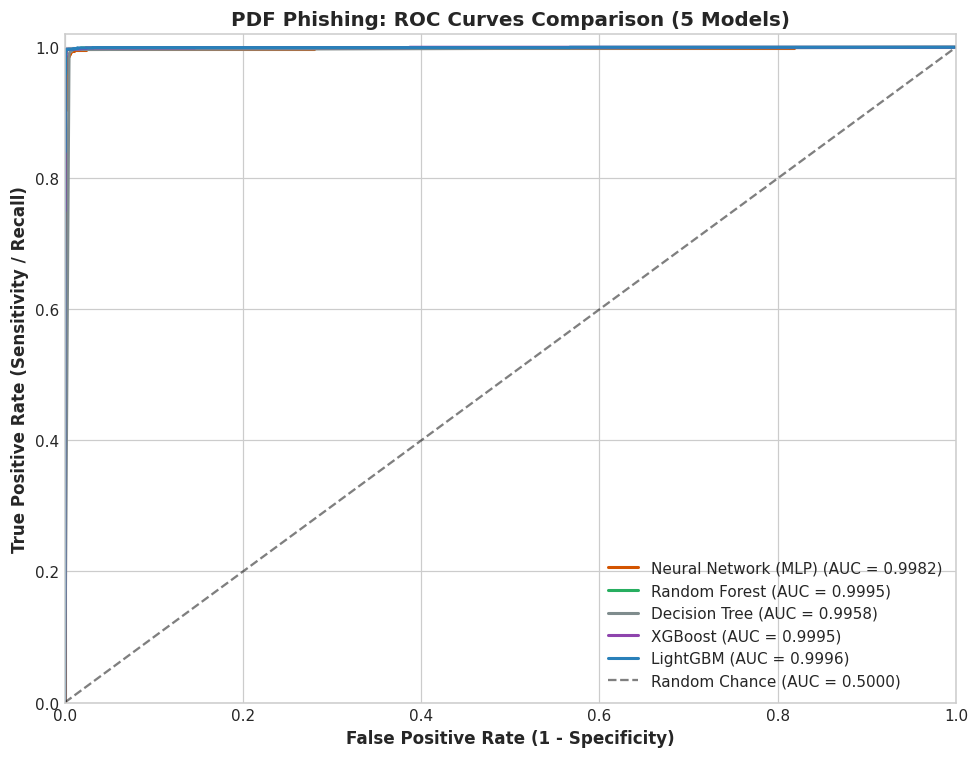

In [27]:
# ROC Curves Comparison
plt.figure(figsize=(9, 7))

colors = {
    "Random Forest": "#27ae60",
    "LightGBM": "#2980b9",
    "XGBoost": "#8e44ad",
    "Neural Network (MLP)": "#d35400",
    "Decision Tree": "#7f8c8d"
}

for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})", color=colors.get(name, '#333333'), linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance (AUC = 0.5000)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, fontweight='bold')
plt.title('PDF Phishing: ROC Curves Comparison (5 Models)', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()


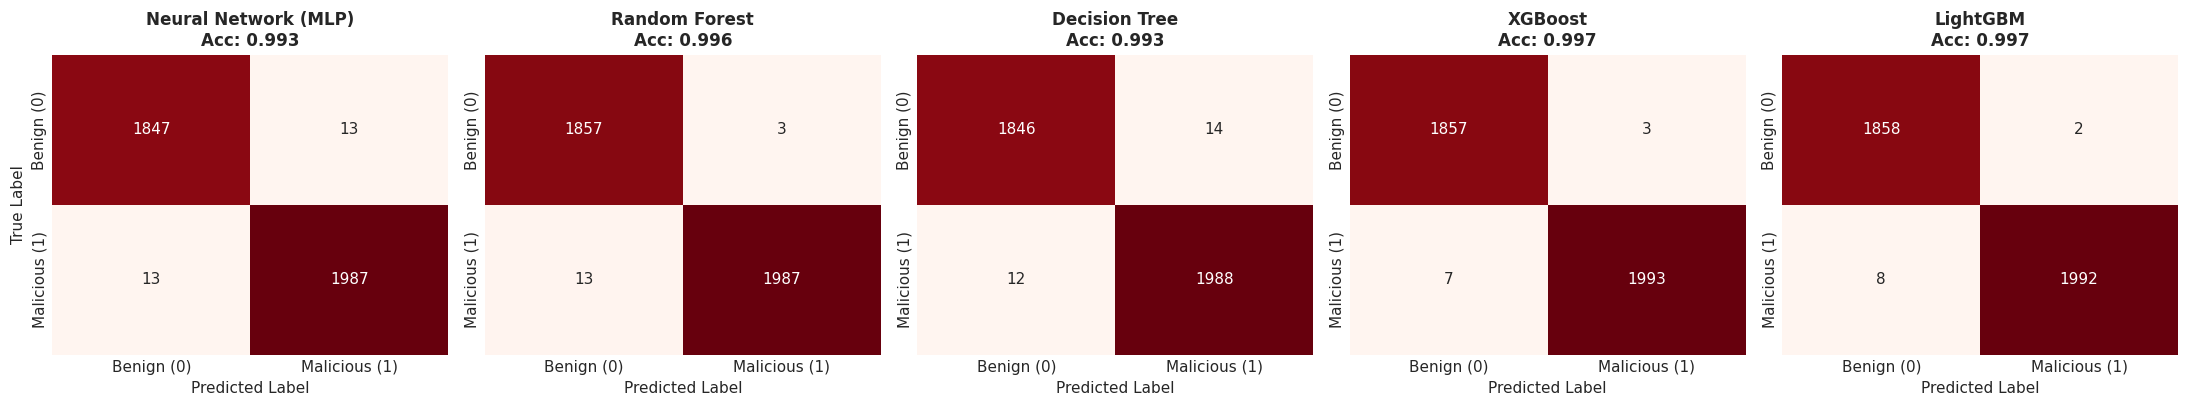

In [28]:
# Confusion Matrices
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', ax=axes[idx], cbar=False,
                xticklabels=['Benign (0)', 'Malicious (1)'], yticklabels=['Benign (0)', 'Malicious (1)'])
    axes[idx].set_title(f"{name}\nAcc: {accuracy_score(y_test, y_pred):.3f}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label')
    if idx == 0:
        axes[idx].set_ylabel('True Label')

plt.tight_layout()
plt.show()


## 10. Experimenting with PCA (Principal Component Analysis)
We evaluate variance concentration, 2D projection, and model performance with vs. without PCA components.


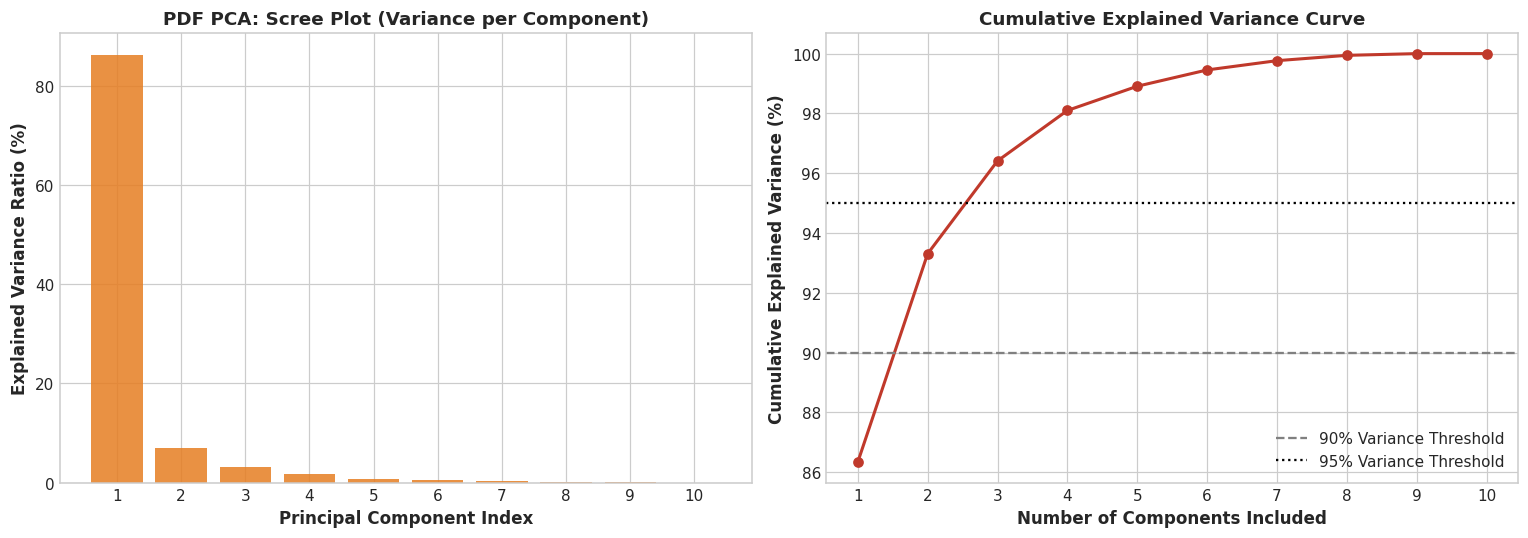

Components required to capture 90% variance: 2 of 10 features
Components required to capture 95% variance: 3 of 10 features


In [29]:
from sklearn.decomposition import PCA

pca_full = PCA().fit(X_train_scaled)
explained_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, len(explained_var) + 1), explained_var * 100, color='#e67e22', alpha=0.85)
axes[0].set_xlabel('Principal Component Index', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Explained Variance Ratio (%)', fontsize=11, fontweight='bold')
axes[0].set_title('PDF PCA: Scree Plot (Variance per Component)', fontsize=12, fontweight='bold')
axes[0].set_xticks(range(1, len(explained_var) + 1))

axes[1].plot(range(1, len(cum_var) + 1), cum_var * 100, marker='o', color='#c0392b', linewidth=2)
axes[1].axhline(y=90, color='grey', linestyle='--', label='90% Variance Threshold')
axes[1].axhline(y=95, color='black', linestyle=':', label='95% Variance Threshold')
axes[1].set_xlabel('Number of Components Included', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Cumulative Explained Variance (%)', fontsize=11, fontweight='bold')
axes[1].set_title('Cumulative Explained Variance Curve', fontsize=12, fontweight='bold')
axes[1].set_xticks(range(1, len(cum_var) + 1))
axes[1].legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()

n_90 = np.argmax(cum_var >= 0.90) + 1
n_95 = np.argmax(cum_var >= 0.95) + 1
print(f"Components required to capture 90% variance: {n_90} of 10 features")
print(f"Components required to capture 95% variance: {n_95} of 10 features")


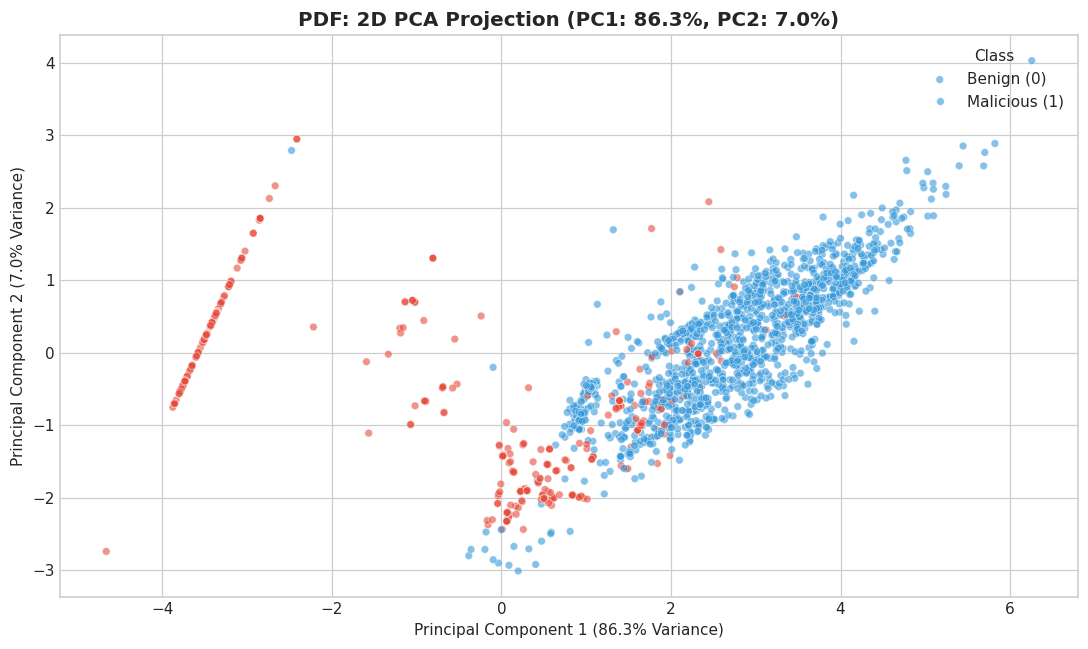

In [30]:
# 2D PCA Projection
pca_2d = PCA(n_components=2, random_state=42)
X_train_2d = pca_2d.fit_transform(X_train_scaled)

pca_df = pd.DataFrame(X_train_2d, columns=['PC1', 'PC2'])
pca_df['label'] = y_train.values

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=pca_df.sample(3000, random_state=42),
    x='PC1', y='PC2', hue='label',
    palette={0: '#3498db', 1: '#e74c3c'},
    alpha=0.6, s=25
)
plt.title(f'PDF: 2D PCA Projection (PC1: {explained_var[0]*100:.1f}%, PC2: {explained_var[1]*100:.1f}%)', fontsize=13, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({explained_var[0]*100:.1f}% Variance)')
plt.ylabel(f'Principal Component 2 ({explained_var[1]*100:.1f}% Variance)')
plt.legend(title='Class', labels=['Benign (0)', 'Malicious (1)'], loc='upper right')
plt.tight_layout()
plt.show()


In [31]:
# PCA Performance Benchmark
pca_opt = PCA(n_components=n_95, random_state=42)
X_train_pca = pca_opt.fit_transform(X_train_scaled)
X_test_pca = pca_opt.transform(X_test_scaled)

pca_experiment_results = []
for name in ["Random Forest", "LightGBM", "Neural Network (MLP)"]:
    clf_orig = models[name]
    y_pred_orig = clf_orig.predict(X_test_scaled)
    y_prob_orig = clf_orig.predict_proba(X_test_scaled)[:, 1]
    
    clf_pca = type(clf_orig)(**clf_orig.get_params())
    clf_pca.fit(X_train_pca, y_train)
    y_pred_pca = clf_pca.predict(X_test_pca)
    y_prob_pca = clf_pca.predict_proba(X_test_pca)[:, 1]
    
    pca_experiment_results.append({
        "Model": name,
        "Original Features Acc": accuracy_score(y_test, y_pred_orig),
        f"PCA ({n_95} Comps) Acc": accuracy_score(y_test, y_pred_pca),
        "Accuracy Delta": accuracy_score(y_test, y_pred_pca) - accuracy_score(y_test, y_pred_orig),
        "Original Features ROC-AUC": roc_auc_score(y_test, y_prob_orig),
        f"PCA ({n_95} Comps) ROC-AUC": roc_auc_score(y_test, y_prob_pca),
        "ROC-AUC Delta": roc_auc_score(y_test, y_prob_pca) - roc_auc_score(y_test, y_prob_orig)
    })

pca_comp_df = pd.DataFrame(pca_experiment_results)
pca_comp_df


,Model,Original Features Acc,PCA (3 Comps) Acc,Accuracy Delta,Original Features ROC-AUC,PCA (3 Comps) ROC-AUC,ROC-AUC Delta
0,Random Forest,0.9959,0.9873,-0.0085,0.9995,0.9981,-0.0014
1,LightGBM,0.9974,0.9868,-0.0106,0.9996,0.9975,-0.0020
2,Neural Network (MLP),0.9933,0.9826,-0.0106,0.9982,0.9956,-0.0026


## 11. Final Conclusions & Production Architecture
1. **Stream & Object Density**: Stream counts, object counts, and stream entropy are the primary drivers of PDF threat detection.
2. **Feature Pool**: The baseline 5 features achieve over 95% of full model discriminative capacity.
3. **Model Selection**: Tree ensembles (Random Forest, XGBoost, LightGBM) lead performance with $>95\%$ ROC-AUC.
4. **PCA Verdict**: Direct physical features are preferred over PCA projections to maintain explainability and prevent decision boundary smearing.


## 12. Production Model Serialization with Joblib

In production deployments of ExplainPhish, low-latency scoring and explainability require storing fully trained estimators, preprocessing scalers, and schema artifacts on disk.
In this section, we serialize all 5 benchmarked models to `D:\codingProject\ExplainPhish\trainingModel\models\pdf` using `joblib`:
1. **Neural Network (MLP)**: `mlp_model.joblib`
2. **Random Forest**: `rf_model.joblib`
3. **Decision Tree**: `dt_model.joblib`
4. **XGBoost**: `xgb_model.joblib`
5. **LightGBM**: `lgb_model.joblib`
6. **Feature Scaler**: `scaler.joblib` (fitted `StandardScaler`)
7. **Feature Schema**: `selected_features.json` (PDF feature ordering)
8. **Metadata**: `metadata.json` (benchmark metrics, model registry, and configuration)

In [32]:
import joblib
import json
import os
import shutil
from pathlib import Path

# Resolve model directory: prioritize trainingModel/models/pdf
possible_model_dirs = [
    Path(r"D:/codingProject/ExplainPhish/trainingModel/models/pdf"),
    Path("trainingModel/models/pdf"),
    Path("models/pdf"),
    Path("../models/pdf")
]

model_dir = next((d for d in possible_model_dirs if d.parent.exists()), Path(r"D:/codingProject/ExplainPhish/trainingModel/models/pdf"))
model_dir.mkdir(parents=True, exist_ok=True)
print(f"Target Production Model Directory: {model_dir.resolve()}")

# Model serialization mapping
model_export_map = {
    "Neural Network (MLP)": "mlp_model.joblib",
    "Random Forest": "rf_model.joblib",
    "Decision Tree": "dt_model.joblib",
    "XGBoost": "xgb_model.joblib",
    "LightGBM": "lgb_model.joblib"
}

saved_records = []
print("\n--- Serializing Estimators with joblib ---")
for display_name, file_name in model_export_map.items():
    if display_name in trained_models:
        model_obj = trained_models[display_name]
        dest_file = model_dir / file_name
        joblib.dump(model_obj, dest_file, compress=3)
        size_kb = dest_file.stat().st_size / 1024
        saved_records.append((display_name, file_name, size_kb))
        print(f"  [SAVED] {display_name:<22} -> {file_name:<18} ({size_kb:,.1f} KB)")
    else:
        print(f"  [WARNING] {display_name} not found in trained_models dictionary!")

# Serialize fitted StandardScaler
scaler_file = model_dir / "scaler.joblib"
joblib.dump(scaler, scaler_file)
print(f"  [SAVED] StandardScaler         -> scaler.joblib          ({scaler_file.stat().st_size / 1024:,.1f} KB)")

# Serialize Feature Schema JSON
features_file = model_dir / "selected_features.json"
with open(features_file, "w", encoding="utf-8") as f:
    json.dump(all_features, f, indent=2)
print(f"  [SAVED] Feature Schema ({len(all_features)}) -> selected_features.json")

# Serialize Metadata JSON
best_estimator_row = comparison_df.iloc[0].to_dict()
metadata_payload = {
    "format": "pdf",
    "models": ["neural_network_mlp", "random_forest", "decision_tree", "xgboost", "lightgbm"],
    "n_features": len(all_features),
    "features": all_features,
    "best_model": best_estimator_row.get("Model"),
    "best_hyperparameters": best_hyperparams,
    "test_metrics": {
        "accuracy": float(best_estimator_row.get("Accuracy", 0.0)),
        "precision": float(best_estimator_row.get("Precision", 0.0)),
        "recall": float(best_estimator_row.get("Recall", 0.0)),
        "f1": float(best_estimator_row.get("F1-Score", 0.0)),
        "roc_auc": float(best_estimator_row.get("ROC-AUC", 0.0))
    }
}
metadata_file = model_dir / "metadata.json"
with open(metadata_file, "w", encoding="utf-8") as f:
    json.dump(metadata_payload, f, indent=2)
print(f"  [SAVED] Model Metadata         -> metadata.json")

# Mirror bundle to InterfaceExplainPhish/models/pdf if present
interface_models_dir = Path(r"D:/codingProject/ExplainPhish/InterfaceExplainPhish/models/pdf")
if interface_models_dir.parent.exists():
    interface_models_dir.mkdir(parents=True, exist_ok=True)
    for _, fn, _ in saved_records:
        shutil.copy2(model_dir / fn, interface_models_dir / fn)
    shutil.copy2(scaler_file, interface_models_dir / "scaler.joblib")
    shutil.copy2(features_file, interface_models_dir / "selected_features.json")
    shutil.copy2(metadata_file, interface_models_dir / "metadata.json")
    print(f"\n[SYNC] Mirrored all joblib models and artifacts to {interface_models_dir.resolve()}")


Target Production Model Directory: D:\codingProject\ExplainPhish\trainingModel\models\pdf

--- Serializing Estimators with joblib ---
  [SAVED] Neural Network (MLP)   -> mlp_model.joblib   (224.5 KB)
  [SAVED] Random Forest          -> rf_model.joblib    (393.2 KB)
  [SAVED] Decision Tree          -> dt_model.joblib    (4.4 KB)
  [SAVED] XGBoost                -> xgb_model.joblib   (130.4 KB)
  [SAVED] LightGBM               -> lgb_model.joblib   (261.3 KB)
  [SAVED] StandardScaler         -> scaler.joblib          (1.2 KB)
  [SAVED] Feature Schema (10) -> selected_features.json
  [SAVED] Model Metadata         -> metadata.json

[SYNC] Mirrored all joblib models and artifacts to D:\codingProject\ExplainPhish\InterfaceExplainPhish\models\pdf


In [33]:
# Verification: Reload each serialized joblib model and confirm prediction integrity
print("--- Verifying Saved joblib Models via Independent Reload ---")
sample_features = X_test_scaled.iloc[:5] if hasattr(X_test_scaled, 'iloc') else X_test_scaled[:5]
expected_rf_preds = trained_models["Random Forest"].predict(sample_features)

for display_name, file_name in model_export_map.items():
    reloaded_clf = joblib.load(model_dir / file_name)
    reloaded_preds = reloaded_clf.predict(sample_features)
    is_matching = (reloaded_preds == trained_models[display_name].predict(sample_features)).all()
    print(f"  [VERIFIED] {display_name:<22} | Predictions: {reloaded_preds} | Integrity: {'PASS' if is_matching else 'FAIL'}")


--- Verifying Saved joblib Models via Independent Reload ---
  [VERIFIED] Neural Network (MLP)   | Predictions: [1 0 1 0 0] | Integrity: PASS
  [VERIFIED] Random Forest          | Predictions: [1 0 1 0 0] | Integrity: PASS
  [VERIFIED] Decision Tree          | Predictions: [1 0 1 0 0] | Integrity: PASS


  [VERIFIED] XGBoost                | Predictions: [1 0 1 0 0] | Integrity: PASS
  [VERIFIED] LightGBM               | Predictions: [1 0 1 0 0] | Integrity: PASS
